# Simulating Timed Transfers and Bus Holding at Borella for Kadawatha-Pettah Metro Passengers

*Provenance: Human-written, then edited with AI.*

Running direct Metro buses between every origin and destination is impractical and would put more buses on already congested roads; coordinating existing Metro routes at shared stops, so passengers can transfer reliably, is a cheaper alternative. This notebook tests that idea at Borella, where Lanka Metro Transit routes CM01 (Makumbura-Colombo Fort/Pettah) and CM03 (Makumbura-Kadawatha) meet, and where Kadawatha-Pettah Metro passengers must transfer because no direct Metro service links the two. When traffic delays a feeder bus, transferring passengers miss their connection, but holding the connecting bus delays passengers already on board. A three-layer stochastic discrete-event simulation models this trade-off: a discrete-time Markov chain for road congestion, stop-by-stop Poisson boarding and alighting with an 80-passenger capacity, and a Borella interchange layer for transfer queueing and holding rules. After passing fifteen analytical, limiting-case, conservation and variance-reduction checks, the model compares schedule-based holding, real-time ETA-based holding and timetable shifts using common random numbers and 95% confidence intervals. On the current timetable 15.4% of transfers are missed; shifting CM01 by +10 min with real-time holding of up to 10 min reduces this to 11.0% using the existing 5 CM01 and 6 CM03 buses, while one extra bus placed to even out headways does not reduce missed connections.

In [1]:
!pip install -q numpy pandas scipy matplotlib

zsh:1: command not found: pip


In [2]:
import heapq
import io
import math
import zlib
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.stats import norm

SEED = 42  # master seed: every random number in the notebook comes from this


def experiment_seeds(experiment_name, n_streams):
    # Each experiment gets its own seed streams, keyed by its name,
    # so re-running or changing one experiment does not change another's results.
    stream_key = zlib.crc32(experiment_name.encode("utf-8"))
    return np.random.SeedSequence(SEED, spawn_key=(stream_key,)).spawn(n_streams)

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
    "axes.titlesize": 11.5,
    "axes.labelsize": 10,
})

# Save figures to <repo>/figures when run from notebook/, otherwise to ./figures (repo root or Colab's /content)
FIGURES_DIR = Path("../figures") if Path("../data/timetables").exists() else Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"SEED = {SEED}")
print(f"numpy {np.__version__}, scipy {scipy.__version__}, matplotlib {plt.matplotlib.__version__}, pandas {pd.__version__}")

SEED = 42
numpy 2.5.5, scipy 1.18.1, matplotlib 3.11.2, pandas 3.1.1


## 1. Problem and question

*Provenance: AI-generated, then modified.*

Two Lanka Metro Transit routes intersect at Borella in Colombo:

- **Route CM01:** Makumbura to Colombo Fort/Pettah via Sethsiripaya, Rajagiriya, **Borella (Singer Mega)**, and Town Hall (12 daily trips per direction).
- **Route CM03:** Makumbura to Kadawatha via Apeksha Hospital, Nawinna, Narahenpita Junction, **Borella 02 (YMBA)**, Cambell Park, and Kelaniya University (12 northbound trips, 11 southbound trips).

No single route connects Kadawatha directly with Pettah. Introducing a part-paid through-ticket with one transfer at Borella serves two simultaneous passenger streams. The passenger pays part of the fare on the first bus and the balance on the connecting bus, provided they board it within the ticket validity window (proposed: 2 hours). Seats are not reserved, so boarding at Borella is first come, first served: a passenger who cannot board waits for the next Metro bus or leaves to use other transport.

| Transfer group | Trip direction | Feeder bus leg | Connecting bus leg |
|---|---|---|---|
| Group A | Kadawatha to Pettah | `CM03_KAD_to_MAK` | `CM01_MAK_to_FOR` |
| Group B | Pettah to Kadawatha | `CM01_FOR_to_MAK` | `CM03_MAK_to_KAD` |

Only Lanka Metro Transit buses are modelled, because the through-ticket works within one operator; private and CTB buses count as other transport.

Because CM01 and CM03 operate on 30-to-120-minute headways without coordinated Borella transfer windows, traffic variability, stop dwell times, and full buses ($C = 80$) make connections unreliable, and missing a connection imposes roughly an hour of extra waiting.

**Question:** What holding rule (no holding, schedule-based holding, or real-time ETA-based holding) and timetable adjustment at Borella keep missed connections low for both directions without delaying passengers already on board too much, and can this make through-ticketing viable on the current fleet without adding buses? Policies are ranked by the cost $J$ (Section 2), which combines transfer waiting, missed connections and on-board holding. Every recommended timetable keeps fixed, published departure times at the terminals.

## 2. Model, assumptions and equations

*Provenance: AI-generated.*

### Concepts and Methods Applied

| Modelling concept | Role in this simulator | Equations and code routines |
|---|---|---|
| Discrete-event simulation and queueing | Primary: stop-level FIFO passenger queues and `heapq` Borella transfer event loop with tie-breaking | `simulate_leg_day`, `simulate_direction_transfers` |
| Input modelling and random variate generation | Primary: inverse-transform exponential arrivals with thinning for the time-varying rate, uniform destinations, discrete Markov lookup, Knuth Poisson counts, Box-Muller normal ETA noise | `sample_thinned_arrival_times`, `sample_discrete_state`, `sample_poisson_knuth`, `sample_standard_normal_box_muller` |
| Markov chains (DTMC) | Supporting: 3-state peak/off-peak traffic congestion chain calibrated via stationary distribution and bisection | `build_parametric_transition_matrix`, `compute_stationary_distribution`, `calibrate_jam_param_bisection` |
| Monte Carlo integration and law of large numbers | Supporting: multi-day replication ensembles with common random numbers (`SeedSequence`), 95% confidence intervals, and $O(R^{-1/2})$ convergence scaling | `precompute_day_inputs`, `summarize_ci`, convergence check X2 |

### Timetable Cleaning, Borella Interpolation, and Target Mapping

- **Timetable cleaning (`CM03-MAK-02`):** Trip `CM03-MAK-02` (05:45 from Makumbura) exhibits a $+60\text{ min}$ offset on intermediate columns (`Nawinna` 07:18 through `Kelaniya University` 08:47), while its origin (`05:45`) and destination (`08:05`) match the standard 140-minute runtime. Subtracting $60\text{ min}$ from those four intermediate columns restores strict monotonicity across all timepoints.
- **Borella interpolation:** Borella is not a published timepoint. Given bracketing scheduled timepoints $T_{\text{prev}}$ and $T_{\text{next}}$, Borella is placed in proportion to road distance, with $d_{\text{prev}\to B}$ and $d_{B\to\text{next}}$ taken from OSRM routing on OpenStreetMap roads:

$$\lambda_\ell = \frac{d_{\text{prev}\to B}}{d_{\text{prev}\to B} + d_{B\to\text{next}}}, \qquad T_{\text{Borella,sched}} = T_{\text{prev}} + \lambda_\ell \left(T_{\text{next}} - T_{\text{prev}}\right)$$

  This gives $\lambda = 0.509$ (CM01 to Fort), $0.435$ (CM01 to Makumbura), $0.764$ (CM03 to Kadawatha) and $0.254$ (CM03 to Makumbura). It assumes constant speed between the two timepoints.

- **Target connector mapping:** Each feeder trip $f$ is assigned to the earliest opposite-direction connector trip $c(f)$ whose scheduled Borella time satisfies $T_{c,\text{sched}} \ge T_{f,\text{sched}}$ (or labelled `out_of_window` if no later connector exists). With walking time $w = 3.5\text{ min}$, the scheduled transfer slack is:

$$s_f = T_{c(f),\text{sched}} - \left(T_{f,\text{sched}} + w\right)$$

  Positive slack ($s_f > 0$) gives a scheduled buffer. The tightest pairs are the afternoon Group A connections `CM03-KAD-05..08` ($s_f = 6.6\text{ min}$) and the morning Group B `CM01-FOR-03` ($s_f = 8.4\text{ min}$): feasible on paper, but traffic delays of that size are common. With a midpoint placement ($\lambda = 0.5$) the same pairs would have $s_f = -0.5\text{ min}$, so the result depends on where Borella sits between timepoints.

### Layer 1: Discrete-Time Markov Traffic Model

Each corridor evolves on $\Delta t = 5\text{ min}$ slots over three congestion states $S_t \in \{0:\text{Free},\, 1:\text{Slow},\, 2:\text{Jammed}\}$ with state speeds $v = (36, 20, 10)\text{ km/h}$ when the `cmb_traffic` corridor file is available (the default) or $v = (30, 15, 5)\text{ km/h}$ in the synthetic fallback. The higher empirical values keep the observed off-peak target inside the reachable bracket $[\bar{v}(0.85), \bar{v}(0.01)]$. Peak windows are 06:00-09:00 and 17:00-20:00 (Amalan, 2021). Using jam-tendency parameter $p \in [0.01, 0.85]$:

$$P(p) = \begin{pmatrix} 1 - p & 0.7p & 0.3p \\ 0.4(1 - p) & 0.4 & 0.2 + 0.4p \\ 0.1(1 - p) & 0.3(1 - p) & 0.6 + 0.4p \end{pmatrix}$$

The stationary distribution $\pi^*(p)$ solves $\pi^*(p) P(p) = \pi^*(p)$ with $\sum_k \pi^*_k = 1$, giving stationary mean speed $\bar{v}(p) = \sum_{k=0}^2 \pi^*_k(p) v_k$. Bisection solves for $p_{\text{offpeak}}$ and $p_{\text{peak}}$ against the mean speed of the six `cmb_traffic` corridors ($29.37$ and $24.10\text{ km/h}$; synthetic fallback $22.0$ and $14.0\text{ km/h}$). Given state $i$ and $U \sim \text{Uniform}(0, 1)$, transitions use explicit inverse-transform cumulative lookup:

$$j = \min\left\{k \in \{0, 1, 2\} : \sum_{m=0}^{k} P_{i,m} \ge U\right\}$$

Per-leg bus speed scale factors $\alpha_{\ell}$ are calibrated by bisection so mean simulated origin-to-Borella runtime matches the published timetable runtime within $1\%$.

### Layer 2: Stop-by-Stop Bus Journey, Arrivals, and Dwell Time

At each stop $s$, passenger arrivals begin $30\text{ min}$ before the leg's first scheduled departure with rate $\lambda_s(t) = \lambda_{s,0} \cdot m(t)$, where $m(t) = 1.35$ during peak periods and $0.85$ off-peak. This non-homogeneous Poisson process is sampled exactly by thinning (Lewis-Shedler): candidates are drawn at the maximum rate $\lambda^{\max}_s = 1.35\,\lambda_{s,0}$ by inverse transform and each is kept with probability $\lambda_s(t)/\lambda^{\max}_s$:

$$\Delta\tau = -\frac{\ln(1 - U_1)}{\lambda^{\max}_s}, \qquad \text{accept if } U_2 \le \frac{\lambda_s(t)}{\lambda^{\max}_s}, \qquad d \sim \text{Uniform}\{s+1, \dots, n_{\text{stops}}-1\}$$

At stop $s$, $a_s$ on-board passengers alight, and $b_s = \min(q_s, C - (\text{load}_s - a_s))$ waiting passengers board in FIFO order up to bus capacity $C = 80$. Stop dwell time is linear:

$$t_{\text{dwell},s} = \frac{t_{\text{door}} + t_{\text{alight}}\, a_s + t_{\text{board}}\, b_s}{60}\quad [\text{min}]$$

with $t_{\text{door}} = 12\text{ s}$, $t_{\text{alight}} = 2\text{ s/pax}$, and $t_{\text{board}} = 3\text{ s/pax}$.

### Layer 3: Borella Transfer Queueing, Holding Policies, and Objective

Each feeder trip $f$ carries $m_f \sim \text{Poisson}(5)$ through-ticket passengers (Knuth algorithm) who become ready at $T_{f,\text{ready}} = T_{f,\text{arr,Borella}} + w$. Buses keep their published times only at the origin terminal, so a connector leaves Borella as soon as it has served the stop:

$$T_{c,\text{base}} = T_{c,\text{arr,Borella}} + t_{c,\text{dwell}}$$

Let $\mathcal{F}_c = \{f : c(f) = c\}$ be the protected feeders targeting connector $c$, and let $T_{c,\text{cap}} = T_{c,\text{base}} + h$ be the latest departure allowed by holding:

1. **No holding (`none`):** Connector $c$ departs at $T_{c,\text{dep}} = T_{c,\text{base}}$.
2. **Schedule holding (`schedule`):** Connector $c$ waits for all protected feeders, up to the cap:

$$T_{c,\text{dep}} = \min\left(T_{c,\text{cap}},\; \max\left(T_{c,\text{base}},\; \max_{f \in \mathcal{F}_c} T_{f,\text{ready}}\right)\right)$$

3. **Real-time ETA holding (`realtime`):** Using estimated feeder ready time $\hat{T}_{f,\text{ready}} = T_{f,\text{ready}} + \varepsilon_f$ with $\varepsilon_f \sim \mathcal{N}(0, \sigma_{\text{eta}}^2)$ generated via Box-Muller transform, the connector protects only feeders predicted to be catchable, $\mathcal{F}_c^{\text{ETA}} = \{f \in \mathcal{F}_c : \hat{T}_{f,\text{ready}} \le T_{c,\text{cap}}\}$, and skips holding if $\mathcal{F}_c^{\text{ETA}}$ is empty or already ready.

**First-come, first-served boarding.** Local Borella passengers and through-ticket passengers form one queue ordered by arrival time and board up to $C - N_c$ free places, where $N_c$ is the connector load after Borella alighting. No seats are reserved.

**Patience and ticket validity.** A passenger who misses the planned connector (timing miss) or is refused by a full bus (capacity miss) waits for the next connector only if it is scheduled within the patience limit $P$ of the current time $t$ and within the ticket validity $V$ of their arrival at Borella:

$$\text{wait} \iff T_{\text{next,sched}} - t \le P \quad\text{and}\quad T_{\text{next,sched}} - T_{f,\text{ready}} \le V$$

Otherwise the passenger is **lost** to other transport and is charged the time already waited plus an alternative-travel penalty $\pi_{\text{alt}}$. The same patience rule applies to local passengers left behind by full buses at every stop. Feeder trips with no later connector in the day (`out_of_window`) send all their passengers to other transport at cost $\pi_{\text{alt}}$, so a timetable shift cannot lower the cost by pushing passengers out of the analysis window.

Policy performance is evaluated via expected daily equivalent passenger-minutes:

$$J(h, \Delta) = w_{\text{wait}}\, \mathbb{E}\left[\sum_{i} (w + W_i) + \pi_{\text{alt}} N_{\text{oow}}\right] + w_{\text{hold}}\, \mathbb{E}\left[\sum_{b} N_b \cdot \text{hold}_b\right], \qquad w_{\text{wait}} = 2.0,\; w_{\text{hold}} = 1.0$$

where $w$ is the walk between the two Borella stops, $W_i$ is the wait at the connector stop of in-window passenger $i$ (including $\pi_{\text{alt}}$ when lost) and $N_{\text{oow}}$ is the number of out-of-window passengers. Counting the walk keeps a longer interchange walk from looking cheaper.

### Fleet, Timing Point and Extra Bus

- **Buses needed by a timetable:** trips are linked into bus duties: a bus can run trip $j$ after trip $i$ if $j$ starts at the terminal where $i$ ends and $T_{j,\text{dep}} \ge T_{i,\text{arr}} + \tau$, with turnaround $\tau = 10\text{ min}$ (the shortest turnaround in the published timetables). The fewest buses equals the number of trips minus a maximum matching on this "can follow" graph (minimum path cover). CM01 and CM03 buses do not swap routes. A whole-route shift $\Delta$ moves every trip of the route by the same amount, so all turnarounds and the bus count are unchanged.
- **Borella timing point:** a connector never leaves Borella before its published Borella time: $T_{c,\text{base}} = \max(T_{c,\text{sched}},\, T_{c,\text{arr}} + t_{c,\text{dwell}})$. Time spent waiting for the published time is charged as on-board hold time in $J$.
- **One extra bus:** the extra bus makes round trips from Makumbura with the route's scheduled run times and $\tau = 10$ min, until its next Makumbura departure would be after the route's last one. Its first departure (5-min grid) minimises $\sum_k h_k^2$ over the terminal headways $h_k$ (a random passenger waits $\sum h_k^2 / 2\sum h_k$ on average). The rule uses the timetable only, never transfer results. Through demand stays fixed: extra feeder trips carry no through passengers.
- **Turnaround reliability:** a planned turnaround is late when the simulated terminal arrival plus $\tau$ is after the next trip's published departure. Borella holding is not added, so this is a lower bound.

### Parameter Summary and Data Provenance

| Parameter | Baseline value | Unit | Provenance / status |
|---|---|---|---|
| Schedules (CM01, CM03) | 47 daily trips | HH:MM | Empirical: LMT-GO app (10 Nov 2026), cross-checked on metrobus.lk |
| Bus capacity $C$ | 80 | pax | Empirical: LMT-GO bus specification |
| Peak windows | 06:00-09:00, 17:00-20:00 | HH:MM | Literature: Amalan (2021) |
| Dwell parameters ($t_{\text{door}}, t_{\text{alight}}, t_{\text{board}}$) | 12, 2, 3 | s, s/pax | Literature-anchored typical urban bus dwell values |
| Segment distances | Leg arrays | km | Empirical: OSRM road routing on OpenStreetMap between geocoded stops (`scripts/build_corridor_geometry.py`) |
| Borella fraction $\lambda_\ell$ | 0.509, 0.435, 0.764, 0.254 | - | Derived from the road distances above |
| Walk time $w$ | 3.5 (2.0-6.5 swept) | min | Placeholder; the OSM walking route between the geocoded stops is 536 m (about 6.5 min) |
| Off-peak / peak target speeds | 29.37 / 24.10 | km/h | Empirical: mean of six `cmb_traffic` corridors (synthetic fallback 22.0 / 14.0 when the file is absent) |
| Base stop arrival rates $\lambda_{s,0}$ | 0.10-0.45 | pax/min | Synthetic/calibrated to Amalan (2021) 55-95% off-peak and 93-140% peak loads |
| Transfer demand mean $m$ | 5.0 | pax/feeder | Synthetic assumption (tested across 3-8 in sensitivity analysis) |
| Passenger patience $P$ | 60 (30-120 swept) | min | Assumption: about one off-peak headway; the part-paid ticket encourages waiting |
| Ticket validity $V$ | 120 | min | Proposed fare-integration rule (part-paid ticket valid for 2 hours) |
| Alternative-travel penalty $\pi_{\text{alt}}$ | 60 | min | Assumption |
| Connector waits for Borella schedule | No (Yes tested as a scenario) | - | Assumption: buses keep published times only at the origin terminal |

## 3. Implementation

*Provenance: AI-generated.*

In [3]:
WALK_TIME_PLACEHOLDER_MIN = 3.5  # min, Borella 02 (YMBA) to Borella (Singer Mega); placeholder until measured

# Stop-to-stop road distances (km) along each direction, from OSRM routing on OpenStreetMap roads
# (scripts/build_corridor_geometry.py, side-street detours to off-road stop coordinates removed).
# base_arrival_rate_pax_per_min: placeholder stop demand (pax/min) before the peak/off-peak multiplier.
ROUTE_LEGS_CONFIG = {
    "CM01_MAK_to_FOR": {
        "stops": ["Makumbura", "Sethsiripaya", "Rajagiriya", "Borella (Singer Mega)", "Town Hall", "Colombo Fort"],
        "segment_distances_km": [11.45, 2.76, 1.95, 1.88, 3.50],
        "borella_idx": 3,
        "base_arrival_rate_pax_per_min": [0.45, 0.35, 0.30, 0.20, 0.12, 0.0],
    },
    "CM01_FOR_to_MAK": {
        "stops": ["Colombo Fort", "Pettah", "Town Hall", "Borella (Singer Mega)", "Rajagiriya", "Sethsiripaya", "Makumbura"],
        "segment_distances_km": [0.90, 4.18, 1.85, 2.40, 2.67, 11.29],
        "borella_idx": 3,
        "base_arrival_rate_pax_per_min": [0.30, 0.35, 0.25, 0.20, 0.15, 0.10, 0.0],
    },
    "CM03_MAK_to_KAD": {
        "stops": ["Makumbura", "Apeksha Hospital", "Nawinna", "Narahenpita Junction", "Borella 02 (YMBA)", "Cambell Park", "Kelaniya University", "Kadawatha"],
        "segment_distances_km": [5.98, 1.12, 7.20, 2.36, 0.73, 8.96, 5.78],
        "borella_idx": 4,
        "base_arrival_rate_pax_per_min": [0.32, 0.20, 0.20, 0.25, 0.20, 0.15, 0.10, 0.0],
    },
    "CM03_KAD_to_MAK": {
        "stops": ["Kadawatha", "Kelaniya University", "Cambell Park", "Borella 02 (YMBA)", "Narahenpita Junction", "Nawinna", "Apeksha Hospital", "Makumbura"],
        "segment_distances_km": [5.90, 8.63, 0.80, 2.35, 7.17, 1.18, 5.85],
        "borella_idx": 3,
        "base_arrival_rate_pax_per_min": [0.28, 0.20, 0.20, 0.20, 0.15, 0.12, 0.10, 0.0],
    },
}

EMBEDDED_TIMETABLES = {
    "cm01_makumbura_to_fort.csv": (
        "trip_id,Makumbura,Sethsiripaya,Rajagiriya,Town Hall,Colombo Fort\n"
        "CM01-MAK-01,05:30,06:22,06:37,07:01,07:20\n"
        "CM01-MAK-02,06:15,07:07,07:22,07:46,08:05\n"
        "CM01-MAK-03,06:45,07:37,07:52,08:16,08:35\n"
        "CM01-MAK-04,07:15,08:07,08:22,08:46,09:05\n"
        "CM01-MAK-05,08:15,09:07,09:22,09:46,10:05\n"
        "CM01-MAK-06,09:45,10:37,10:52,11:16,11:35\n"
        "CM01-MAK-07,10:45,11:37,11:52,12:16,12:35\n"
        "CM01-MAK-08,12:15,13:07,13:22,13:46,14:05\n"
        "CM01-MAK-09,13:30,14:22,14:37,15:01,15:20\n"
        "CM01-MAK-10,14:30,15:22,15:37,16:01,16:20\n"
        "CM01-MAK-11,15:30,16:22,16:37,17:01,17:20\n"
        "CM01-MAK-12,16:30,17:22,17:37,18:01,18:20\n"
    ),
    "cm01_fort_to_makumbura.csv": (
        "trip_id,Colombo Fort,Pettah,Town Hall,Rajagiriya,Sethsiripaya,Makumbura\n"
        "CM01-FOR-01,07:30,07:32,07:49,08:13,08:28,09:20\n"
        "CM01-FOR-02,08:15,08:17,08:34,08:58,09:13,10:05\n"
        "CM01-FOR-03,08:45,08:47,09:04,09:28,09:43,10:35\n"
        "CM01-FOR-04,09:30,09:32,09:49,10:13,10:28,11:20\n"
        "CM01-FOR-05,10:30,10:32,10:49,11:13,11:28,12:20\n"
        "CM01-FOR-06,12:00,12:02,12:19,12:43,12:58,13:50\n"
        "CM01-FOR-07,13:30,13:32,13:49,14:13,14:28,15:20\n"
        "CM01-FOR-08,14:30,14:32,14:49,15:13,15:28,16:20\n"
        "CM01-FOR-09,15:30,15:32,15:49,16:13,16:28,17:20\n"
        "CM01-FOR-10,16:30,16:32,16:49,17:13,17:28,18:20\n"
        "CM01-FOR-11,17:30,17:32,17:49,18:13,18:28,19:20\n"
        "CM01-FOR-12,18:30,18:32,18:49,19:13,19:28,20:20\n"
    ),
    "cm03_makumbura_to_kadawatha.csv": (
        "trip_id,Makumbura,Apeksha Hospital,Nawinna,Narahenpita Junction,Cambell Park,Kelaniya University,Kadawatha\n"
        "CM03-MAK-01,05:00,05:25,05:33,06:05,06:33,07:02,07:20\n"
        "CM03-MAK-02,05:45,06:10,07:18,07:50,08:18,08:47,08:05\n"
        "CM03-MAK-03,07:00,07:25,07:33,08:05,08:33,09:02,09:20\n"
        "CM03-MAK-04,08:00,08:25,08:33,09:05,09:33,10:02,10:20\n"
        "CM03-MAK-05,09:00,09:25,09:33,10:05,10:33,11:02,11:20\n"
        "CM03-MAK-06,11:00,11:25,11:33,12:05,12:33,13:02,13:20\n"
        "CM03-MAK-07,12:00,12:25,12:33,13:05,13:33,14:02,14:20\n"
        "CM03-MAK-08,13:00,13:25,13:33,14:05,14:33,15:02,15:20\n"
        "CM03-MAK-09,14:00,14:25,14:33,15:05,15:33,16:02,16:20\n"
        "CM03-MAK-10,15:00,15:25,15:33,16:05,16:33,17:02,17:20\n"
        "CM03-MAK-11,16:15,16:40,16:48,17:20,17:48,18:17,18:35\n"
        "CM03-MAK-12,17:15,17:40,17:48,18:20,18:48,19:17,19:35\n"
    ),
    "cm03_kadawatha_to_makumbura.csv": (
        "trip_id,Kadawatha,Kelaniya University,Cambell Park,Narahenpita Junction,Nawinna,Apeksha Hospital,Makumbura\n"
        "CM03-KAD-01,07:45,08:03,08:32,09:00,09:32,09:40,10:05\n"
        "CM03-KAD-02,09:45,10:03,10:32,11:00,11:32,11:40,12:05\n"
        "CM03-KAD-03,10:45,11:03,11:32,12:00,12:32,12:40,13:05\n"
        "CM03-KAD-04,11:45,12:03,12:32,13:00,13:32,13:40,14:05\n"
        "CM03-KAD-05,13:45,14:03,14:32,15:00,15:32,15:40,16:05\n"
        "CM03-KAD-06,14:45,15:03,15:32,16:00,16:32,16:40,17:05\n"
        "CM03-KAD-07,15:45,16:03,16:32,17:00,17:32,17:40,18:05\n"
        "CM03-KAD-08,16:45,17:03,17:32,18:00,18:32,18:40,19:05\n"
        "CM03-KAD-09,17:45,18:03,18:32,19:00,19:32,19:40,20:05\n"
        "CM03-KAD-10,19:15,19:33,20:02,20:30,21:02,21:10,21:35\n"
        "CM03-KAD-11,19:45,20:03,20:32,21:00,21:32,21:40,22:05\n"
    ),
}


def parse_hhmm_to_minutes(hhmm_str):
    hours, minutes = map(int, hhmm_str.strip().split(":"))
    return float(hours * 60 + minutes)


def format_minutes_to_hhmm(total_min):
    if pd.isna(total_min):
        return "--:--"
    rounded_min = int(round(total_min))
    return f"{rounded_min // 60:02d}:{rounded_min % 60:02d}"


GITHUB_RAW_BASE_URL = "https://raw.githubusercontent.com/nayanthanethsara/metro-transfer-simulator/main"


def load_raw_timetable(filename):
    for candidate in (Path("data/timetables") / filename, Path("../data/timetables") / filename):
        if candidate.exists():
            return pd.read_csv(candidate), str(candidate)
    raw_url = f"{GITHUB_RAW_BASE_URL}/data/timetables/{filename}"
    try:
        return pd.read_csv(raw_url), raw_url
    except Exception:
        return pd.read_csv(io.StringIO(EMBEDDED_TIMETABLES[filename])), "embedded"


def convert_timetable_to_minutes(df):
    result = df.copy()
    for col in result.columns:
        if col != "trip_id":
            result[col] = result[col].map(parse_hhmm_to_minutes)
    return result


def clean_cm03_mak_to_kad(df):
    # The source lists four CM03-MAK-02 timepoints one hour late (Nawinna 07:18 after Apeksha 06:10; Kelaniya 08:47 after Kadawatha 08:05).
    cleaned = df.copy()
    cleaning_log = []
    shifted_cols = ["Nawinna", "Narahenpita Junction", "Cambell Park", "Kelaniya University"]
    mask = cleaned["trip_id"] == "CM03-MAK-02"
    if mask.any():
        for col in shifted_cols:
            before_str = format_minutes_to_hhmm(cleaned.loc[mask, col].iloc[0])
            cleaned.loc[mask, col] = cleaned.loc[mask, col] - 60.0
            after_str = format_minutes_to_hhmm(cleaned.loc[mask, col].iloc[0])
            cleaning_log.append(f"CM03-MAK-02 {col}: {before_str} -> {after_str} (-60 min)")
    timepoint_cols = [c for c in cleaned.columns if c != "trip_id"]
    diffs = cleaned[timepoint_cols].diff(axis=1).iloc[:, 1:]
    assert (diffs > 0).all().all(), "Non-monotonic timepoints remain after cleaning"
    return cleaned, cleaning_log


def borella_road_fraction(leg_cfg):
    # Share of the road distance between the bracketing timepoints that lies before Borella.
    b = leg_cfg["borella_idx"]
    before_km = leg_cfg["segment_distances_km"][b - 1]
    after_km = leg_cfg["segment_distances_km"][b]
    return before_km / (before_km + after_km)


def build_borella_schedule(df, leg_name):
    leg_cfg = ROUTE_LEGS_CONFIG[leg_name]
    b = leg_cfg["borella_idx"]
    prev_stop, next_stop = leg_cfg["stops"][b - 1], leg_cfg["stops"][b + 1]
    fraction = borella_road_fraction(leg_cfg)
    out = pd.DataFrame({
        "leg": leg_name,
        "trip_id": df["trip_id"],
        "origin_sched_min": df[df.columns[1]],
        "borella_sched_min": df[prev_stop] + fraction * (df[next_stop] - df[prev_stop]),
        "dest_sched_min": df[df.columns[-1]],
    })
    out["borella_sched_hhmm"] = out["borella_sched_min"].map(format_minutes_to_hhmm)
    return out


def map_target_connectors(feeders_df, connectors_df, walk_time_min, group_name):
    # Target = first connector scheduled at Borella no earlier than the feeder. The walk is not required
    # to fit, so a negative slack marks a connection that is infeasible on paper.
    conn_sorted = connectors_df.sort_values("borella_sched_min").reset_index(drop=True)
    rows = []
    for _, feeder in feeders_df.sort_values("borella_sched_min").iterrows():
        feeder_sched = float(feeder["borella_sched_min"])
        ready_min = feeder_sched + walk_time_min
        eligible = conn_sorted[conn_sorted["borella_sched_min"] >= feeder_sched - 1e-9]
        if eligible.empty:
            target_id = None
            target_borella_min = np.nan
            slack_min = np.nan
            status = "out_of_window"
        else:
            target = eligible.iloc[0]
            target_id = target["trip_id"]
            target_borella_min = float(target["borella_sched_min"])
            slack_min = round(target_borella_min - ready_min, 2)
            status = "in_window"
        rows.append({
            "group": group_name,
            "feeder_trip_id": feeder["trip_id"],
            "feeder_borella_hhmm": feeder["borella_sched_hhmm"],
            "ready_hhmm": format_minutes_to_hhmm(ready_min),
            "target_connector_id": target_id,
            "connector_borella_hhmm": format_minutes_to_hhmm(target_borella_min),
            "scheduled_slack_min": slack_min,
            "window_status": status,
        })
    return pd.DataFrame(rows)


raw_cm01_mak, src_1 = load_raw_timetable("cm01_makumbura_to_fort.csv")
raw_cm01_for, src_2 = load_raw_timetable("cm01_fort_to_makumbura.csv")
raw_cm03_mak, src_3 = load_raw_timetable("cm03_makumbura_to_kadawatha.csv")
raw_cm03_kad, src_4 = load_raw_timetable("cm03_kadawatha_to_makumbura.csv")

cm01_mak_min = convert_timetable_to_minutes(raw_cm01_mak)
cm01_for_min = convert_timetable_to_minutes(raw_cm01_for)
cm03_mak_min_raw = convert_timetable_to_minutes(raw_cm03_mak)
cm03_kad_min = convert_timetable_to_minutes(raw_cm03_kad)

cm03_mak_min, cleaning_log = clean_cm03_mak_to_kad(cm03_mak_min_raw)

sched_cm01_mak = build_borella_schedule(cm01_mak_min, "CM01_MAK_to_FOR")
sched_cm01_for = build_borella_schedule(cm01_for_min, "CM01_FOR_to_MAK")
sched_cm03_mak = build_borella_schedule(cm03_mak_min, "CM03_MAK_to_KAD")
sched_cm03_kad = build_borella_schedule(cm03_kad_min, "CM03_KAD_to_MAK")
print("Borella road-distance fractions:", {leg: round(borella_road_fraction(cfg), 3) for leg, cfg in ROUTE_LEGS_CONFIG.items()})

transfers_group_a = map_target_connectors(sched_cm03_kad, sched_cm01_mak, WALK_TIME_PLACEHOLDER_MIN, "A_Kadawatha_to_Pettah")
transfers_group_b = map_target_connectors(sched_cm01_for, sched_cm03_mak, WALK_TIME_PLACEHOLDER_MIN, "B_Pettah_to_Kadawatha")

print("Data sources:", [src_1, src_2, src_3, src_4])
print("Cleaning log:", cleaning_log)
print(f"Group A in-window: {(transfers_group_a['window_status'] == 'in_window').sum()}/{len(transfers_group_a)}")
print(transfers_group_a[["feeder_trip_id", "feeder_borella_hhmm", "ready_hhmm", "target_connector_id", "connector_borella_hhmm", "scheduled_slack_min", "window_status"]].to_string(index=False))
print(f"\nGroup B in-window: {(transfers_group_b['window_status'] == 'in_window').sum()}/{len(transfers_group_b)}")
print(transfers_group_b[["feeder_trip_id", "feeder_borella_hhmm", "ready_hhmm", "target_connector_id", "connector_borella_hhmm", "scheduled_slack_min", "window_status"]].to_string(index=False))

Borella road-distance fractions: {'CM01_MAK_to_FOR': 0.509, 'CM01_FOR_to_MAK': 0.435, 'CM03_MAK_to_KAD': 0.764, 'CM03_KAD_to_MAK': 0.254}
Data sources: ['../data/timetables/cm01_makumbura_to_fort.csv', '../data/timetables/cm01_fort_to_makumbura.csv', '../data/timetables/cm03_makumbura_to_kadawatha.csv', '../data/timetables/cm03_kadawatha_to_makumbura.csv']
Cleaning log: ['CM03-MAK-02 Nawinna: 07:18 -> 06:18 (-60 min)', 'CM03-MAK-02 Narahenpita Junction: 07:50 -> 06:50 (-60 min)', 'CM03-MAK-02 Cambell Park: 08:18 -> 07:18 (-60 min)', 'CM03-MAK-02 Kelaniya University: 08:47 -> 07:47 (-60 min)']
Group A in-window: 8/11
feeder_trip_id feeder_borella_hhmm ready_hhmm target_connector_id connector_borella_hhmm  scheduled_slack_min window_status
   CM03-KAD-01               08:39      08:43         CM01-MAK-05                  09:34                51.61     in_window
   CM03-KAD-02               10:39      10:43         CM01-MAK-06                  11:04                21.61     in_window
   C

In [4]:
STATE_NAMES = ("Free", "Slow", "Jammed")
SYNTHETIC_STATE_SPEEDS_KMPH = np.array([30.0, 15.0, 5.0])  # km/h, fallback if no traffic data is found
EMPIRICAL_STATE_SPEEDS_KMPH = np.array([36.0, 20.0, 10.0])  # km/h for Free, Slow, Jammed
STATE_SPEEDS_KMPH = SYNTHETIC_STATE_SPEEDS_KMPH
TRAFFIC_STEP_MIN = 5.0
JAM_PARAM_MIN = 0.01  # bisection bracket for the dimensionless jam parameter p
JAM_PARAM_MAX = 0.85
PEAK_WINDOWS_MIN = ((360.0, 540.0), (1020.0, 1200.0))  # min after midnight: 06:00-09:00 and 17:00-20:00

SYNTHETIC_TARGET_SPEED_OFFPEAK_KMPH = 22.0
SYNTHETIC_TARGET_SPEED_PEAK_KMPH = 14.0


def load_traffic_targets():
    sources = (
        Path("data/traffic/corridor_speeds.csv"),
        Path("../data/traffic/corridor_speeds.csv"),
        f"{GITHUB_RAW_BASE_URL}/data/traffic/corridor_speeds.csv",
    )
    for src in sources:
        if isinstance(src, Path) and not src.exists():
            continue
        try:
            df = pd.read_csv(src)
            off_df = df[df["period"] == "offpeak"]
            peak_df = df[df["period"] == "peak"]
            if not off_df.empty and not peak_df.empty:
                v_off = float(off_df["mean_speed_kmph"].mean())
                v_peak = float(peak_df["mean_speed_kmph"].mean())
                return v_off, v_peak, str(src), df
        except Exception:
            continue
    return (
        SYNTHETIC_TARGET_SPEED_OFFPEAK_KMPH,
        SYNTHETIC_TARGET_SPEED_PEAK_KMPH,
        "synthetic_targets",
        None,
    )


def build_parametric_transition_matrix(jam_param):
    # A single p in [0, 1] shifts probability toward Slow and Jammed.
    p = float(jam_param)
    matrix = np.array([
        [1.0 - p,       0.7 * p,       0.3 * p],
        [0.4 * (1 - p), 0.4,           0.2 + 0.4 * p],
        [0.1 * (1 - p), 0.3 * (1 - p), 0.6 + 0.4 * p],
    ], dtype=float)
    assert np.allclose(matrix.sum(axis=1), 1.0), "Transition rows must sum to 1"
    return matrix


def compute_stationary_distribution(transition_matrix):
    # Solve pi P = pi with sum(pi) = 1 by replacing one row of (P^T - I) pi = 0 with the normalisation.
    n_states = transition_matrix.shape[0]
    system_matrix = transition_matrix.T - np.eye(n_states)
    system_matrix[-1, :] = 1.0
    rhs = np.zeros(n_states)
    rhs[-1] = 1.0
    pi_star = np.linalg.solve(system_matrix, rhs)
    assert np.all(pi_star >= -1e-12) and np.isclose(pi_star.sum(), 1.0)
    return np.clip(pi_star, 0.0, 1.0)


def expected_speed_for_jam_param(jam_param, state_speeds_kmph=None):
    if state_speeds_kmph is None:
        state_speeds_kmph = STATE_SPEEDS_KMPH
    matrix = build_parametric_transition_matrix(jam_param)
    pi_star = compute_stationary_distribution(matrix)
    return float(np.dot(pi_star, state_speeds_kmph))


def calibrate_jam_param_bisection(target_speed_kmph, p_low=JAM_PARAM_MIN, p_high=JAM_PARAM_MAX, tol=1e-6):
    # pi(p) . v decreases in p, so bisection finds the p whose long-run mean speed (km/h) hits the target.
    v_max = expected_speed_for_jam_param(p_low)
    v_min = expected_speed_for_jam_param(p_high)
    assert v_min <= target_speed_kmph <= v_max, (
        f"Target speed {target_speed_kmph:.2f} km/h outside reachable bracket [{v_min:.2f}, {v_max:.2f}]"
    )
    low, high = p_low, p_high
    for _ in range(80):
        mid = 0.5 * (low + high)
        if expected_speed_for_jam_param(mid) > target_speed_kmph:
            low = mid
        else:
            high = mid
        if high - low < tol:
            break
    return 0.5 * (low + high)


def sample_discrete_state(cdf_row, uniform_draw):
    # Inverse-transform sampling on one cumulative transition row.
    for state_idx, cum_prob in enumerate(cdf_row):
        if uniform_draw <= cum_prob:
            return state_idx
    return len(cdf_row) - 1


def simulate_markov_chain_loop(transition_matrix, n_steps, rng, initial_state=0):
    cdf = np.cumsum(transition_matrix, axis=1)
    uniforms = rng.random(n_steps)
    states = np.empty(n_steps, dtype=int)
    state = initial_state
    for step in range(n_steps):
        states[step] = state
        state = sample_discrete_state(cdf[state], uniforms[step])
    return states


def simulate_markov_chain_vectorized(transition_matrix, n_steps, n_chains, rng, initial_state=0):
    cdf = np.cumsum(transition_matrix, axis=1)
    uniforms = rng.random((n_chains, n_steps))
    states = np.empty((n_chains, n_steps), dtype=int)
    current = np.full(n_chains, initial_state, dtype=int)
    for step in range(n_steps):
        states[:, step] = current
        row_cdfs = cdf[current]
        u_col = uniforms[:, step : step + 1]
        current = np.sum(u_col > row_cdfs[:, :-1], axis=1)
    return states


def is_peak_time(time_min):
    return any(start <= time_min < end for start, end in PEAK_WINDOWS_MIN)


target_offpeak_kmph, target_peak_kmph, traffic_source_label, empirical_traffic_df = load_traffic_targets()
if empirical_traffic_df is not None:
    STATE_SPEEDS_KMPH = EMPIRICAL_STATE_SPEEDS_KMPH
p_offpeak = calibrate_jam_param_bisection(target_offpeak_kmph)
p_peak = calibrate_jam_param_bisection(target_peak_kmph)

P_offpeak = build_parametric_transition_matrix(p_offpeak)
P_peak = build_parametric_transition_matrix(p_peak)

pi_offpeak = compute_stationary_distribution(P_offpeak)
pi_peak = compute_stationary_distribution(P_peak)

print(f"Traffic target source: {traffic_source_label}")
print(f"State speeds (Free, Slow, Jammed) = {STATE_SPEEDS_KMPH} km/h, targets: off-peak {target_offpeak_kmph:.2f}, peak {target_peak_kmph:.2f} km/h")
print(f"Calibrated off-peak jam param p = {p_offpeak:.4f}, pi* = {np.round(pi_offpeak, 4)}, E[v] = {np.dot(pi_offpeak, STATE_SPEEDS_KMPH):.2f} km/h")
print(f"Calibrated peak     jam param p = {p_peak:.4f}, pi* = {np.round(pi_peak, 4)}, E[v] = {np.dot(pi_peak, STATE_SPEEDS_KMPH):.2f} km/h")

Traffic target source: ../data/traffic/corridor_speeds.csv
State speeds (Free, Slow, Jammed) = [36. 20. 10.] km/h, targets: off-peak 29.37, peak 24.10 km/h
Calibrated off-peak jam param p = 0.1014, pi* = [0.686  0.1533 0.1606], E[v] = 29.37 km/h
Calibrated peak     jam param p = 0.2181, pi* = [0.4514 0.2368 0.3119], E[v] = 24.10 km/h


In [5]:
CAPACITY_PAX = 80
DOOR_TIME_SEC = 12.0
BOARD_TIME_SEC = 3.0
ALIGHT_TIME_SEC = 2.0
BUS_SPEED_FACTOR_ALPHA = 0.75  # bus speed / car speed before per-leg calibration
DAY_START_MIN = 240.0  # 04:00, min after midnight
DAY_END_MIN = 1440.0  # 24:00
PRE_DEPARTURE_ACCUM_MIN = 30.0
PASSENGER_PATIENCE_MIN = 60.0
PEAK_ARRIVAL_MULTIPLIER = 1.35  # x base stop arrival rate
OFFPEAK_ARRIVAL_MULTIPLIER = 0.85

leg_schedules = {
    "CM01_MAK_to_FOR": sched_cm01_mak,
    "CM01_FOR_to_MAK": sched_cm01_for,
    "CM03_MAK_to_KAD": sched_cm03_mak,
    "CM03_KAD_to_MAK": sched_cm03_kad,
}


def generate_daily_traffic_grid(rng, p_offpeak_mat, p_peak_mat):
    # One state per 5-min slot (+2 h spare so late trips stay on the grid); the matrix follows the slot's peak/off-peak regime.
    n_slots = int((DAY_END_MIN - DAY_START_MIN) / TRAFFIC_STEP_MIN) + 24
    cdf_offpeak = np.cumsum(p_offpeak_mat, axis=1)
    cdf_peak = np.cumsum(p_peak_mat, axis=1)
    uniforms = rng.random(n_slots)
    states = np.empty(n_slots, dtype=int)
    state = 0
    for slot in range(n_slots):
        states[slot] = state
        t_min = DAY_START_MIN + slot * TRAFFIC_STEP_MIN
        cdf = cdf_peak if is_peak_time(t_min) else cdf_offpeak
        state = sample_discrete_state(cdf[state], uniforms[slot])
    return states


def travel_segment_minutes(start_time_min, distance_km, traffic_states, alpha=BUS_SPEED_FACTOR_ALPHA):
    # Drive slot by slot: km covered = (alpha * state speed km/h / 60) * min available in the slot.
    remaining_km = float(distance_km)
    current_time_min = float(start_time_min)
    while remaining_km > 1e-9:
        slot = int(max(0, (current_time_min - DAY_START_MIN) // TRAFFIC_STEP_MIN))
        slot = min(slot, len(traffic_states) - 1)
        slot_end_min = DAY_START_MIN + (slot + 1) * TRAFFIC_STEP_MIN
        avail_min = max(0.01, slot_end_min - current_time_min)
        speed_km_per_min = (alpha * STATE_SPEEDS_KMPH[traffic_states[slot]]) / 60.0
        max_dist_km = speed_km_per_min * avail_min
        if max_dist_km >= remaining_km:
            current_time_min += remaining_km / speed_km_per_min
            remaining_km = 0.0
        else:
            remaining_km -= max_dist_km
            current_time_min = slot_end_min
    return current_time_min - start_time_min


def arrival_rate_multipliers(times_min):
    in_peak = np.zeros(times_min.shape, dtype=bool)
    for start, end in PEAK_WINDOWS_MIN:
        in_peak |= (times_min >= start) & (times_min < end)
    return np.where(in_peak, PEAK_ARRIVAL_MULTIPLIER, OFFPEAK_ARRIVAL_MULTIPLIER)


def sample_thinned_arrival_times(base_rate, start_min, end_min, rng):
    # Lewis-Shedler thinning: homogeneous Poisson candidates at the peak rate (pax/min), each kept with
    # probability lambda(t) / lambda_max. Drawn in vectorised batches until end_min is passed.
    max_rate = base_rate * PEAK_ARRIVAL_MULTIPLIER
    accepted = []
    t0 = start_min
    while t0 < end_min:
        n_draw = int(max_rate * (end_min - t0) * 1.2) + 20
        gaps = -np.log(1.0 - rng.random(n_draw)) / max_rate
        candidates = t0 + np.cumsum(gaps)
        keep_prob = base_rate * arrival_rate_multipliers(candidates) / max_rate
        keep = (candidates < end_min) & (rng.random(n_draw) <= keep_prob)
        accepted.append(candidates[keep])
        t0 = candidates[-1]
    return np.concatenate(accepted) if accepted else np.empty(0)


def generate_stop_arrivals(leg_cfg, first_origin_min, arr_rng, dest_rng, arrival_rate_scale=1.0, end_time_min=DAY_END_MIN):
    n_stops = len(leg_cfg["stops"])
    queues = [[] for _ in range(n_stops)]
    start_window_min = max(DAY_START_MIN, float(first_origin_min) - PRE_DEPARTURE_ACCUM_MIN)
    for stop_idx in range(n_stops - 1):
        base_rate = leg_cfg["base_arrival_rate_pax_per_min"][stop_idx] * arrival_rate_scale
        if base_rate <= 0.0:
            continue
        times = sample_thinned_arrival_times(base_rate, start_window_min, end_time_min, arr_rng)
        # Destination drawn uniformly over the downstream stops.
        n_downstream = n_stops - 1 - stop_idx
        offsets = np.minimum((dest_rng.random(times.size) * n_downstream).astype(int), n_downstream - 1)
        queues[stop_idx] = list(zip(times.tolist(), (stop_idx + 1 + offsets).tolist()))
    return queues


def simulate_leg_day(
    leg_name,
    sched_df,
    leg_cfg,
    traffic_states,
    arr_rng,
    dest_rng,
    capacity_pax=CAPACITY_PAX,
    alpha=BUS_SPEED_FACTOR_ALPHA,
    arrival_rate_scale=1.0,
    return_stats=False,
    pregenerated_queues=None,
    patience_min=PASSENGER_PATIENCE_MIN,
    deferred_boarding_stop_idx=None,
):
    sorted_sched = sched_df.sort_values("origin_sched_min").reset_index(drop=True)
    first_origin_min = float(sorted_sched["origin_sched_min"].iloc[0])
    if pregenerated_queues is None:
        queues = generate_stop_arrivals(leg_cfg, first_origin_min, arr_rng, dest_rng, arrival_rate_scale=arrival_rate_scale)
    else:
        queues = pregenerated_queues
    queue_cursors = [0] * len(leg_cfg["stops"])
    n_stops = len(leg_cfg["stops"])
    borella_idx = leg_cfg["borella_idx"]
    trip_records = []
    max_onboard_observed = 0
    total_abandoned_pax = 0
    origin_times_min = sorted_sched["origin_sched_min"].to_numpy(dtype=float)
    next_headways_min = np.append(np.diff(origin_times_min), np.inf)

    for trip_idx, trip in sorted_sched.iterrows():
        t_curr = float(trip["origin_sched_min"])
        onboard_dests = []
        total_left_behind = 0
        trip_boarded = 0
        trip_alighted = 0
        borella_arr_min = np.nan
        borella_dwell_min = 0.0
        borella_onboard_pax = 0
        terminal_arr_min = np.nan

        for stop_idx in range(n_stops):
            if stop_idx > 0:
                dist_km = leg_cfg["segment_distances_km"][stop_idx - 1]
                t_curr += travel_segment_minutes(t_curr, dist_km, traffic_states, alpha=alpha)

            n_alighting = sum(1 for d in onboard_dests if d == stop_idx)
            trip_alighted += n_alighting
            onboard_dests = [d for d in onboard_dests if d != stop_idx]

            q = queues[stop_idx]
            cursor = queue_cursors[stop_idx]
            waiting_count = 0
            # Connector legs skip boarding at Borella here; it happens in simulate_direction_transfers.
            while stop_idx != deferred_boarding_stop_idx and cursor + waiting_count < len(q) and q[cursor + waiting_count][0] <= t_curr:
                waiting_count += 1

            if capacity_pax is None:
                n_boarding = waiting_count
            else:
                free_seats = max(0, capacity_pax - len(onboard_dests))
                n_boarding = min(waiting_count, free_seats)

            left_here = waiting_count - n_boarding
            total_left_behind += left_here
            trip_boarded += n_boarding
            for k in range(n_boarding):
                onboard_dests.append(q[cursor + k][1])
            queue_cursors[stop_idx] = cursor + n_boarding
            # Left-behind passengers give up if the next scheduled bus is more than patience_min away.
            if left_here > 0 and next_headways_min[trip_idx] > patience_min:
                queue_cursors[stop_idx] += left_here
                total_abandoned_pax += left_here

            max_onboard_observed = max(max_onboard_observed, len(onboard_dests))
            if capacity_pax is not None:
                assert len(onboard_dests) <= capacity_pax, f"Capacity exceeded: {len(onboard_dests)} > {capacity_pax}"

            # Dwell (min) = door time + 2 s per alighting + 3 s per boarding passenger.
            dwell_min = (DOOR_TIME_SEC + ALIGHT_TIME_SEC * n_alighting + BOARD_TIME_SEC * n_boarding) / 60.0
            if stop_idx == borella_idx:
                borella_arr_min = t_curr
                borella_dwell_min = dwell_min
                borella_onboard_pax = len(onboard_dests)
            if stop_idx == n_stops - 1:
                terminal_arr_min = t_curr
            t_curr += dwell_min

        assert len(onboard_dests) == 0, "Passengers remained on board past terminal stop"
        trip_records.append({
            "leg": leg_name,
            "trip_id": trip["trip_id"],
            "borella_sched_hhmm": trip["borella_sched_hhmm"],
            "borella_sim_hhmm": format_minutes_to_hhmm(borella_arr_min),
            "borella_delay_min": round(borella_arr_min - trip["borella_sched_min"], 2),
            "borella_dwell_min": round(borella_dwell_min, 2),
            "borella_onboard_pax": borella_onboard_pax,
            "terminal_arr_min": terminal_arr_min,
            "left_behind_pax": total_left_behind,
            "boarded_pax": trip_boarded,
            "alighted_pax": trip_alighted,
        })

    trip_df = pd.DataFrame(trip_records)
    if return_stats:
        served_stop_indices = [i for i in range(n_stops) if i != deferred_boarding_stop_idx]
        stats = {
            "total_generated_stop_pax": sum(len(queues[i]) for i in served_stop_indices),
            "total_boarded_pax": int(trip_df["boarded_pax"].sum()),
            "total_alighted_pax": int(trip_df["alighted_pax"].sum()),
            "end_of_day_unserved_pax": sum(len(queues[i]) - queue_cursors[i] for i in served_stop_indices),
            "abandoned_pax": total_abandoned_pax,
            "max_onboard_observed": max_onboard_observed,
            "total_left_behind_events": int(trip_df["left_behind_pax"].sum()),
        }
        return trip_df, stats
    return trip_df


N_CAL_DAYS = 120


def calibrate_leg_alphas(n_cal_days=N_CAL_DAYS, tol=0.001):
    # Bisection on alpha per leg so the mean simulated Borella delay over the calibration days is zero.
    cal_seeds = experiment_seeds("calibration", n_cal_days)
    alphas = {}
    cal_rel_errors = {}
    for leg_name, sched_df in leg_schedules.items():
        leg_cfg = ROUTE_LEGS_CONFIG[leg_name]
        sorted_sched = sched_df.sort_values("origin_sched_min").reset_index(drop=True)
        first_origin_min = float(sorted_sched["origin_sched_min"].iloc[0])
        target_runtime_min = float((sched_df["borella_sched_min"] - sched_df["origin_sched_min"]).mean())
        cal_days = []
        for s in cal_seeds:
            sub = s.spawn(3)
            t_grid = generate_daily_traffic_grid(np.random.default_rng(sub[0]), P_offpeak, P_peak)
            queues = generate_stop_arrivals(leg_cfg, first_origin_min, np.random.default_rng(sub[1]), np.random.default_rng(sub[2]))
            cal_days.append((t_grid, queues))

        low, high = 0.25, 2.50
        best_alpha = 0.5 * (low + high)
        best_rel_err = float("inf")
        for _ in range(28):
            mid = 0.5 * (low + high)
            mean_delays = [
                simulate_leg_day(
                    leg_name, sched_df, leg_cfg, t_grid,
                    None, None, alpha=mid, pregenerated_queues=queues
                )["borella_delay_min"].mean()
                for t_grid, queues in cal_days
            ]
            mean_err = float(np.mean(mean_delays))
            rel_err = abs(mean_err) / target_runtime_min
            if rel_err < best_rel_err:
                best_rel_err = rel_err
                best_alpha = mid
            if best_rel_err < tol:
                break
            if mean_err > 0.0:
                low = mid
            else:
                high = mid
        alphas[leg_name] = best_alpha
        cal_rel_errors[leg_name] = best_rel_err
    return alphas, cal_rel_errors


LEG_ALPHAS, LEG_CAL_REL_ERRORS = calibrate_leg_alphas(n_cal_days=N_CAL_DAYS, tol=0.001)
print("Calibrated leg speed factors (alpha):", {k: round(v, 3) for k, v in LEG_ALPHAS.items()})
print("Calibration ensemble relative errors (%):", {k: round(100.0 * v, 3) for k, v in LEG_CAL_REL_ERRORS.items()})

day_streams = experiment_seeds("single_day_preview", 3)
traffic_rng = np.random.default_rng(day_streams[0])
arrivals_rng = np.random.default_rng(day_streams[1])
destinations_rng = np.random.default_rng(day_streams[2])

for leg_name, sched_df in leg_schedules.items():
    t_grid = generate_daily_traffic_grid(traffic_rng, P_offpeak, P_peak)
    sim_df = simulate_leg_day(
        leg_name, sched_df, ROUTE_LEGS_CONFIG[leg_name], t_grid,
        arrivals_rng, destinations_rng, alpha=LEG_ALPHAS[leg_name]
    )
    print(f"\n--- {leg_name} (one simulated day, alpha={LEG_ALPHAS[leg_name]:.3f}) ---")
    print(sim_df[["trip_id", "borella_sched_hhmm", "borella_sim_hhmm", "borella_delay_min", "borella_dwell_min", "borella_onboard_pax", "left_behind_pax"]].to_string(index=False))

Calibrated leg speed factors (alpha): {'CM01_MAK_to_FOR': 0.498, 'CM01_FOR_to_MAK': 0.648, 'CM03_MAK_to_KAD': 0.457, 'CM03_KAD_to_MAK': 0.714}
Calibration ensemble relative errors (%): {'CM01_MAK_to_FOR': 0.026, 'CM01_FOR_to_MAK': 0.064, 'CM03_MAK_to_KAD': 0.075, 'CM03_KAD_to_MAK': 0.005}

--- CM01_MAK_to_FOR (one simulated day, alpha=0.498) ---
    trip_id borella_sched_hhmm borella_sim_hhmm  borella_delay_min  borella_dwell_min  borella_onboard_pax  left_behind_pax
CM01-MAK-01              06:49            06:29             -19.91               1.60                   35                0
CM01-MAK-02              07:34            07:13             -20.90               1.33                   41                0
CM01-MAK-03              08:04            08:02              -2.43               1.25                   36                0
CM01-MAK-04              08:34            08:54              19.54               1.58                   51                0
CM01-MAK-05              09:34  

In [6]:
TRANSFER_MEAN_PAX = 5.0  # mean through passengers per feeder trip (Poisson), placeholder
WAIT_WEIGHT = 2.0  # weight on transfer passenger-minutes in J
HOLD_WEIGHT = 1.0  # weight on on-board hold passenger-minutes in J
ALTERNATIVE_TRAVEL_PENALTY_MIN = 60.0  # min charged to a passenger who gives up and travels another way
TICKET_VALIDITY_MIN = 120.0  # min after becoming ready at Borella
ETA_NOISE_SD_DEFAULT_MIN = 1.0  # min, SD of the real-time feeder ETA error
TRANSFER_CONNECTOR_LEGS = ("CM01_MAK_to_FOR", "CM03_MAK_to_KAD")
HOLDING_POLICIES = ("none", "schedule", "realtime")


def sample_poisson_knuth(mean_val, rng):
    # Knuth: multiply uniforms until the product drops below exp(-mean).
    limit = np.exp(-mean_val)
    k = 0
    prod = 1.0
    while True:
        k += 1
        prod *= rng.random()
        if prod <= limit:
            return k - 1


def sample_standard_normal_box_muller(rng):
    # Box-Muller; 1 - u keeps the log argument above zero.
    u1 = max(1e-12, 1.0 - rng.random())
    u2 = rng.random()
    return float(np.sqrt(-2.0 * np.log(u1)) * np.cos(2.0 * np.pi * u2))


def build_target_lookup(transfers_df):
    return {
        k: (None if pd.isna(v) else str(v))
        for k, v in zip(transfers_df["feeder_trip_id"], transfers_df["target_connector_id"])
    }


TARGET_LOOKUP_CACHE = {}


def get_target_lookups(shifted_scheds, shift_cm01_min, shift_cm03_min, walk_time_min, extra_key=()):
    cache_key = (float(shift_cm01_min), float(shift_cm03_min), float(walk_time_min), extra_key)
    if cache_key not in TARGET_LOOKUP_CACHE:
        TARGET_LOOKUP_CACHE[cache_key] = (
            build_target_lookup(map_target_connectors(shifted_scheds["CM03_KAD_to_MAK"], shifted_scheds["CM01_MAK_to_FOR"], walk_time_min, "A")),
            build_target_lookup(map_target_connectors(shifted_scheds["CM01_FOR_to_MAK"], shifted_scheds["CM03_MAK_to_KAD"], walk_time_min, "B")),
        )
    return TARGET_LOOKUP_CACHE[cache_key]


def precompute_day_inputs(
    rep_seed_seq,
    shift_cm01_min=0.0,
    shift_cm03_min=0.0,
    capacity_pax=CAPACITY_PAX,
    walk_time_min=WALK_TIME_PLACEHOLDER_MIN,
    transfer_mean_pax=TRANSFER_MEAN_PAX,
    arrival_rate_scale=1.0,
    p_offpeak_mat=None,
    p_peak_mat=None,
    leg_alphas=None,
    eta_noise_sd_min=ETA_NOISE_SD_DEFAULT_MIN,
    patience_min=PASSENGER_PATIENCE_MIN,
    connector_waits_for_schedule=False,
    extra_trips=None,
):
    # Draws every random input of one day once. Policies are then evaluated on the same day (common random numbers).
    if p_offpeak_mat is None:
        p_offpeak_mat = P_offpeak
    if p_peak_mat is None:
        p_peak_mat = P_peak
    if leg_alphas is None:
        leg_alphas = LEG_ALPHAS
    if extra_trips is None:
        extra_trips = {}
    extra_trip_ids = {tid for extra_df in extra_trips.values() for tid in extra_df["trip_id"]}

    # Same child streams on every call with this seed (spawn() would give new ones each time), so every
    # scenario built from the same seed sees the same day (common random numbers).
    stream_traffic, stream_arrivals, stream_destinations, stream_transfers, stream_eta = [
        np.random.SeedSequence(rep_seed_seq.entropy, spawn_key=rep_seed_seq.spawn_key + (k,), pool_size=rep_seed_seq.pool_size)
        for k in range(5)
    ]
    t_rng = np.random.default_rng(stream_traffic)
    a_rng = np.random.default_rng(stream_arrivals)
    d_rng = np.random.default_rng(stream_destinations)
    tr_rng = np.random.default_rng(stream_transfers)
    eta_rng = np.random.default_rng(stream_eta)

    shifts = {
        "CM01_MAK_to_FOR": shift_cm01_min,
        "CM01_FOR_to_MAK": shift_cm01_min,
        "CM03_MAK_to_KAD": shift_cm03_min,
        "CM03_KAD_to_MAK": shift_cm03_min,
    }

    shifted_scheds = {}
    leg_runs = {}
    borella_local_queues = {}
    for leg_name, base_df in leg_schedules.items():
        df = base_df.copy()
        for col in ("origin_sched_min", "borella_sched_min", "dest_sched_min"):
            df[col] += shifts[leg_name]
        df["borella_sched_hhmm"] = df["borella_sched_min"].map(format_minutes_to_hhmm)
        first_origin_min = float(df["origin_sched_min"].min())
        if leg_name in extra_trips:
            # Extra trips are already in final timetable times, so they are not shifted again.
            df = pd.concat([df, extra_trips[leg_name]], ignore_index=True)
        shifted_scheds[leg_name] = df

        leg_cfg = ROUTE_LEGS_CONFIG[leg_name]
        traffic_grid = generate_daily_traffic_grid(t_rng, p_offpeak_mat, p_peak_mat)
        stop_queues = generate_stop_arrivals(
            leg_cfg, first_origin_min, a_rng, d_rng, arrival_rate_scale=arrival_rate_scale
        )
        deferred_stop_idx = leg_cfg["borella_idx"] if leg_name in TRANSFER_CONNECTOR_LEGS else None
        sim_df = simulate_leg_day(
            leg_name,
            df,
            leg_cfg,
            traffic_grid,
            None,
            None,
            capacity_pax=capacity_pax,
            alpha=leg_alphas[leg_name],
            pregenerated_queues=stop_queues,
            patience_min=patience_min,
            deferred_boarding_stop_idx=deferred_stop_idx,
        )
        if deferred_stop_idx is not None:
            borella_local_queues[leg_name] = [arrival_min for arrival_min, _ in stop_queues[deferred_stop_idx]]

        merged = df.merge(
            sim_df[["trip_id", "borella_delay_min", "borella_dwell_min", "borella_onboard_pax", "terminal_arr_min"]],
            on="trip_id",
        )
        merged["borella_arr_min"] = merged["borella_sched_min"] + merged["borella_delay_min"]
        # Holding is measured from the natural departure (arrival + dwell), not the timetable.
        natural_dep_min = merged["borella_arr_min"] + merged["borella_dwell_min"]
        merged["borella_natural_dep_min"] = natural_dep_min
        if connector_waits_for_schedule:
            merged["borella_base_dep_min"] = np.maximum(merged["borella_sched_min"], natural_dep_min)
        else:
            merged["borella_base_dep_min"] = natural_dep_min
        leg_runs[leg_name] = merged

    target_a, target_b = get_target_lookups(
        shifted_scheds, shift_cm01_min, shift_cm03_min, walk_time_min, extra_key=tuple(sorted(extra_trip_ids))
    )

    transfer_counts = {}
    eta_errors = {}
    for leg_name in ("CM03_KAD_to_MAK", "CM01_FOR_to_MAK"):
        for trip_id in leg_runs[leg_name]["trip_id"]:
            if trip_id in extra_trip_ids:
                # Through demand stays fixed: extra feeder trips carry no through passengers.
                transfer_counts[trip_id] = 0
                eta_errors[trip_id] = 0.0
                continue
            transfer_counts[trip_id] = sample_poisson_knuth(transfer_mean_pax, tr_rng)
            eta_errors[trip_id] = eta_noise_sd_min * sample_standard_normal_box_muller(eta_rng)

    return {
        "leg_runs": leg_runs,
        "leg_records": {leg: as_records(df) for leg, df in leg_runs.items()},
        "target_a": target_a,
        "target_b": target_b,
        "transfer_counts": transfer_counts,
        "eta_errors": eta_errors,
        "borella_local_queues": borella_local_queues,
        "patience_min": patience_min,
    }


def as_records(trips):
    return trips if isinstance(trips, list) else list(trips.itertuples(index=False))


def simulate_direction_transfers(
    feeders_df,
    connectors_df,
    target_lookup,
    transfer_counts,
    eta_errors,
    policy,
    hold_max_min,
    walk_time_min,
    capacity_pax,
    local_arrival_times=(),
    patience_min=PASSENGER_PATIENCE_MIN,
    ticket_validity_min=TICKET_VALIDITY_MIN,
    wait_weight=WAIT_WEIGHT,
    hold_weight=HOLD_WEIGHT,
):
    # Borella event loop for one transfer direction. At equal times FEEDER_READY (priority 0) runs before
    # CONNECTOR_CHECK (priority 1), so a passenger ready exactly at departure still boards.
    if policy not in HOLDING_POLICIES:
        raise ValueError(f"Unknown holding policy: {policy}")
    is_holding_active = policy != "none" and hold_max_min > 0.0

    connectors = as_records(connectors_df)
    feeders = as_records(feeders_df)
    connector_order = [c.trip_id for c in sorted(connectors, key=lambda c: c.borella_sched_min)]
    conn_info = {
        c.trip_id: {
            "sched_min": float(c.borella_sched_min),
            "t_base": float(c.borella_base_dep_min),
            # Departure without any waiting at Borella; hold cost is measured from here.
            "t_natural": float(getattr(c, "borella_natural_dep_min", c.borella_base_dep_min)),
            "onboard_pax": int(c.borella_onboard_pax),
            "departed": False,
        }
        for c in connectors
    }

    feeder_ready = {}
    protected_feeders = {cid: set() for cid in conn_info}
    for f in feeders:
        feeder_ready[f.trip_id] = float(f.borella_arr_min) + walk_time_min
        target_cid = target_lookup.get(f.trip_id)
        if target_cid in protected_feeders:
            protected_feeders[target_cid].add(f.trip_id)

    promising_feeders = {}
    for cid, info in conn_info.items():
        if policy == "realtime" and is_holding_active:
            # Real-time holding waits only for feeders whose noisy ETA reaches Borella before the hold deadline.
            latest_dep_min = info["t_base"] + hold_max_min
            promising_feeders[cid] = {
                fid for fid in protected_feeders[cid]
                if feeder_ready[fid] + float(eta_errors.get(fid, 0.0)) <= latest_dep_min + 1e-9
            }
        else:
            promising_feeders[cid] = protected_feeders[cid]

    event_heap = []
    seq = 0
    for fid, ready_min in feeder_ready.items():
        heapq.heappush(event_heap, (ready_min, 0, seq, "FEEDER_READY", fid))
        seq += 1
    for cid, info in conn_info.items():
        heapq.heappush(event_heap, (info["t_base"], 1, seq, "CONNECTOR_CHECK", cid))
        seq += 1

    counts = {"made": 0, "missed_timing": 0, "missed_capacity": 0, "lost_timing": 0, "lost_capacity": 0, "out_of_window": 0}
    totals = {"wait_min": 0.0, "hold_pax_min": 0.0, "local_abandoned": 0}
    waiting_queue = []
    ready_feeders = set()
    boarded_wait_mins = []
    held_durations = []
    local_cursor = 0
    first_open_idx = 0

    def next_open_connector():
        nonlocal first_open_idx
        while first_open_idx < len(connector_order) and conn_info[connector_order[first_open_idx]]["departed"]:
            first_open_idx += 1
        return connector_order[first_open_idx] if first_open_idx < len(connector_order) else None

    def will_wait_for_next_bus(now_min, ready_min):
        # Stay only if the next bus is within patience and departs inside ticket validity.
        next_cid = next_open_connector()
        if next_cid is None:
            return False
        next_sched_min = conn_info[next_cid]["sched_min"]
        return next_sched_min - now_min <= patience_min and next_sched_min - ready_min <= ticket_validity_min

    def finalize_lost(reason, now_min, ready_min):
        counts[f"missed_{reason}"] += 1
        counts[f"lost_{reason}"] += 1
        totals["wait_min"] += (now_min - ready_min) + ALTERNATIVE_TRAVEL_PENALTY_MIN

    def finalize_boarded(pax, dep_min):
        wait_min = max(0.0, dep_min - pax["ready_min"])
        totals["wait_min"] += wait_min
        boarded_wait_mins.append(wait_min)
        if pax["miss_reason"] is None:
            counts["made"] += 1
        else:
            counts[f"missed_{pax['miss_reason']}"] += 1

    def depart_connector(cid, dep_min):
        nonlocal local_cursor
        info = conn_info[cid]
        if info["departed"]:
            return
        info["departed"] = True
        hold_min = max(0.0, dep_min - info["t_natural"])
        totals["hold_pax_min"] += info["onboard_pax"] * hold_min
        if hold_min > 1e-6:
            held_durations.append(hold_min)

        n_local_present = 0
        while (
            local_cursor + n_local_present < len(local_arrival_times)
            and local_arrival_times[local_cursor + n_local_present] <= dep_min + 1e-9
        ):
            n_local_present += 1
        # First come first served by ready time; at a tie, transfer passengers (0) board before locals (1).
        boarding_queue = sorted(
            [(local_arrival_times[local_cursor + k], 1, -1) for k in range(n_local_present)]
            + [(pax["ready_min"], 0, idx) for idx, pax in enumerate(waiting_queue)]
        )
        free_seats = len(boarding_queue) if capacity_pax is None else max(0, capacity_pax - info["onboard_pax"])
        boarded = boarding_queue[:free_seats]
        boarded_transfer_idx = {idx for _, kind, idx in boarded if kind == 0}
        n_local_boarded = sum(1 for _, kind, _ in boarded if kind == 1)

        remaining_queue = []
        for idx, pax in enumerate(waiting_queue):
            if idx in boarded_transfer_idx:
                finalize_boarded(pax, dep_min)
                continue
            if pax["miss_reason"] is None and pax["target_cid"] == cid:
                pax["miss_reason"] = "capacity"
            if pax["miss_reason"] is None or will_wait_for_next_bus(dep_min, pax["ready_min"]):
                remaining_queue.append(pax)
            else:
                finalize_lost(pax["miss_reason"], dep_min, pax["ready_min"])
        waiting_queue[:] = remaining_queue

        n_local_left = n_local_present - n_local_boarded
        if n_local_left > 0 and not will_wait_for_next_bus(dep_min, dep_min):
            totals["local_abandoned"] += n_local_left
            local_cursor += n_local_present
        else:
            local_cursor += n_local_boarded

    while event_heap:
        t_curr, _, _, event_type, obj_id = heapq.heappop(event_heap)
        if event_type == "FEEDER_READY":
            fid = obj_id
            ready_feeders.add(fid)
            n_pax = transfer_counts[fid]
            target_cid = target_lookup.get(fid)
            if target_cid is None:
                counts["out_of_window"] += n_pax
                continue
            target_info = conn_info[target_cid]
            if target_info["departed"]:
                stays = will_wait_for_next_bus(t_curr, t_curr)
                for _ in range(n_pax):
                    if stays:
                        waiting_queue.append({"ready_min": t_curr, "target_cid": target_cid, "miss_reason": "timing"})
                    else:
                        finalize_lost("timing", t_curr, t_curr)
                continue
            waiting_queue.extend({"ready_min": t_curr, "target_cid": target_cid, "miss_reason": None} for _ in range(n_pax))
            if (
                t_curr >= target_info["t_base"] - 1e-9
                and fid in promising_feeders[target_cid]
                and promising_feeders[target_cid] <= ready_feeders
            ):
                depart_connector(target_cid, t_curr)
        else:
            cid = obj_id
            info = conn_info[cid]
            if info["departed"]:
                continue
            deadline_min = info["t_base"] + hold_max_min
            if not is_holding_active or promising_feeders[cid] <= ready_feeders or t_curr >= deadline_min - 1e-9:
                depart_connector(cid, t_curr)
            else:
                heapq.heappush(event_heap, (deadline_min, 1, seq, "CONNECTOR_CHECK", cid))
                seq += 1

    for pax in waiting_queue:
        finalize_lost(pax["miss_reason"] or "timing", pax["ready_min"], pax["ready_min"])

    in_window_total = counts["made"] + counts["missed_timing"] + counts["missed_capacity"]
    out_of_window_penalty_min = counts["out_of_window"] * ALTERNATIVE_TRAVEL_PENALTY_MIN
    total_walk_min = walk_time_min * in_window_total
    # J (pax-min) = wait_weight * (walk + wait + penalties) + hold_weight * on-board hold.
    wait_cost = wait_weight * (total_walk_min + totals["wait_min"] + out_of_window_penalty_min)
    hold_cost = hold_weight * totals["hold_pax_min"]
    return {
        **counts,
        "missed_total": counts["missed_timing"] + counts["missed_capacity"],
        "lost_total": counts["lost_timing"] + counts["lost_capacity"],
        "in_window_total": in_window_total,
        "total_generated": in_window_total + counts["out_of_window"],
        "total_wait_min": totals["wait_min"],
        "total_walk_min": total_walk_min,
        "mean_wait_min": totals["wait_min"] / max(1, in_window_total),
        "boarded_wait_mins": boarded_wait_mins,
        "total_hold_pax_min": totals["hold_pax_min"],
        "wait_cost": wait_cost,
        "hold_cost": hold_cost,
        "total_cost": wait_cost + hold_cost,
        "n_connectors_held": len(held_durations),
        "mean_hold_when_held_min": float(np.mean(held_durations)) if held_durations else 0.0,
        "local_borella_abandoned": totals["local_abandoned"],
    }


TRANSFER_DIRECTIONS = {
    "A": ("CM03_KAD_to_MAK", "CM01_MAK_to_FOR", "target_a"),
    "B": ("CM01_FOR_to_MAK", "CM03_MAK_to_KAD", "target_b"),
}


def evaluate_day(
    day_inputs,
    policy="schedule",
    hold_max_min=0.0,
    walk_time_min=WALK_TIME_PLACEHOLDER_MIN,
    capacity_pax=CAPACITY_PAX,
    wait_weight=WAIT_WEIGHT,
    hold_weight=HOLD_WEIGHT,
    ticket_validity_min=TICKET_VALIDITY_MIN,
):
    return {
        group: simulate_direction_transfers(
            day_inputs["leg_records"][feeder_leg],
            day_inputs["leg_records"][connector_leg],
            day_inputs[target_key],
            day_inputs["transfer_counts"],
            day_inputs["eta_errors"],
            policy,
            hold_max_min,
            walk_time_min,
            capacity_pax,
            local_arrival_times=day_inputs["borella_local_queues"][connector_leg],
            patience_min=day_inputs["patience_min"],
            ticket_validity_min=ticket_validity_min,
            wait_weight=wait_weight,
            hold_weight=hold_weight,
        )
        for group, (feeder_leg, connector_leg, target_key) in TRANSFER_DIRECTIONS.items()
    }


sample_day = precompute_day_inputs(experiment_seeds("sample_day", 1)[0])
for policy_test, h_test in (("none", 0.0), ("schedule", 3.0), ("realtime", 3.0), ("schedule", 6.0)):
    out = evaluate_day(sample_day, policy=policy_test, hold_max_min=h_test)
    miss_a = out["A"]["missed_total"] / max(1, out["A"]["in_window_total"])
    miss_b = out["B"]["missed_total"] / max(1, out["B"]["in_window_total"])
    lost_all = (out["A"]["lost_total"] + out["B"]["lost_total"]) / max(1, out["A"]["in_window_total"] + out["B"]["in_window_total"])
    tot_j = out["A"]["total_cost"] + out["B"]["total_cost"]
    hold_cost_tot = out["A"]["hold_cost"] + out["B"]["hold_cost"]
    print(f"Sample day [{policy_test:8s}, h={h_test:.1f}] -> miss_A={miss_a:5.1%}, miss_B={miss_b:5.1%}, lost={lost_all:5.1%}, hold_cost={hold_cost_tot:6.1f}, J={tot_j:7.1f} pax-min")


Sample day [none    , h=0.0] -> miss_A=31.7%, miss_B= 9.1%, lost= 7.3%, hold_cost=   0.0, J=12283.7 pax-min
Sample day [schedule, h=3.0] -> miss_A=31.7%, miss_B= 9.1%, lost= 7.3%, hold_cost= 144.0, J=12427.7 pax-min
Sample day [realtime, h=3.0] -> miss_A=31.7%, miss_B= 9.1%, lost= 7.3%, hold_cost=   0.0, J=12283.7 pax-min
Sample day [schedule, h=6.0] -> miss_A=31.7%, miss_B= 9.1%, lost= 7.3%, hold_cost= 288.0, J=12571.7 pax-min


In [7]:
MIN_TURNAROUND_MIN = 10.0  # min, shortest terminal turnaround; the published timetables use 10 min
ROUTES = ("CM01", "CM03")


def route_trip_list(scheds, route):
    # (trip_id, from terminal, to terminal, departure, arrival) for every trip of one route, times in min after midnight.
    trips = []
    for leg_name, df in scheds.items():
        leg_route, from_term, _, to_term = leg_name.split("_")
        if leg_route != route:
            continue
        for row in df.itertuples(index=False):
            trips.append((row.trip_id, from_term, to_term, float(row.origin_sched_min), float(row.dest_sched_min)))
    return trips


def bus_blocks(trips, min_turnaround_min=MIN_TURNAROUND_MIN):
    # Fewest buses that run every trip (minimum path cover). A bus can run trip j after trip i if j starts
    # where i ends, at least min_turnaround_min later. Maximum matching by augmenting paths links trips into bus duties.
    n = len(trips)
    can_follow = [
        [j for j in range(n) if trips[j][1] == trips[i][2] and trips[j][3] >= trips[i][4] + min_turnaround_min - 1e-9]
        for i in range(n)
    ]
    prev_of = [-1] * n

    def try_link(i, seen):
        for j in can_follow[i]:
            if j in seen:
                continue
            seen.add(j)
            if prev_of[j] == -1 or try_link(prev_of[j], seen):
                prev_of[j] = i
                return True
        return False

    for i in range(n):
        try_link(i, set())
    next_of = {prev_of[j]: j for j in range(n) if prev_of[j] != -1}
    blocks = []
    for start in sorted((i for i in range(n) if prev_of[i] == -1), key=lambda k: trips[k][3]):
        block = [start]
        while block[-1] in next_of:
            block.append(next_of[block[-1]])
        blocks.append([trips[k] for k in block])
    return blocks


def shifted_schedules(shift_cm01_min=0.0, shift_cm03_min=0.0):
    # Published timetables with a whole-route shift (both directions of the route move together).
    out = {}
    for leg_name, base_df in leg_schedules.items():
        delta = shift_cm01_min if leg_name.startswith("CM01") else shift_cm03_min
        df = base_df.copy()
        for col in ("origin_sched_min", "borella_sched_min", "dest_sched_min"):
            df[col] += delta
        df["borella_sched_hhmm"] = df["borella_sched_min"].map(format_minutes_to_hhmm)
        out[leg_name] = df
    return out


def with_extra_trips(scheds, extra):
    return {leg: pd.concat([df, extra[leg]], ignore_index=True) if leg in extra else df for leg, df in scheds.items()}


def extra_bus_trips(scheds, route, first_dep_min):
    # One extra bus making round trips from Makumbura with the route's scheduled run times and a
    # MIN_TURNAROUND_MIN turnaround, until its next Makumbura departure would be after the route's last one.
    out_leg = next(leg for leg in scheds if leg.startswith(route + "_MAK_to_"))
    back_leg = next(leg for leg in scheds if leg.startswith(route) and leg.endswith("_to_MAK"))
    last_mak_dep_min = float(scheds[out_leg]["origin_sched_min"].max())
    rows = {out_leg: [], back_leg: []}
    t = float(first_dep_min)
    while t <= last_mak_dep_min + 1e-9:
        for leg in (out_leg, back_leg):
            base = scheds[leg]
            run_min = float((base["dest_sched_min"] - base["origin_sched_min"]).median())
            to_borella_min = float((base["borella_sched_min"] - base["origin_sched_min"]).median())
            rows[leg].append({
                "leg": leg,
                "trip_id": f"X-{leg}-{format_minutes_to_hhmm(t)}",
                "origin_sched_min": t,
                "borella_sched_min": t + to_borella_min,
                "dest_sched_min": t + run_min,
                "borella_sched_hhmm": format_minutes_to_hhmm(t + to_borella_min),
            })
            t += run_min + MIN_TURNAROUND_MIN
    return {leg: pd.DataFrame(r) for leg, r in rows.items()}


def headway_score(scheds, route, extra):
    # Sum of squared gaps between departures at each terminal; a passenger arriving at random waits on
    # average sum(h^2) / (2 sum(h)), so smaller is better. Uses the timetable only, never transfer results.
    score = 0.0
    for leg, df in with_extra_trips(scheds, extra).items():
        if leg.startswith(route):
            gaps = np.diff(np.sort(df["origin_sched_min"].to_numpy(dtype=float)))
            score += float(np.sum(gaps ** 2))
    return score


def best_extra_bus(scheds, route, step_min=5.0):
    # Place the extra bus by its first Makumbura departure (5-min grid) to even out the headways.
    out_leg = next(leg for leg in scheds if leg.startswith(route + "_MAK_to_"))
    first_mak_dep_min = float(scheds[out_leg]["origin_sched_min"].min())
    cycle_min = sum(
        float((scheds[leg]["dest_sched_min"] - scheds[leg]["origin_sched_min"]).median()) + MIN_TURNAROUND_MIN
        for leg in scheds if leg.startswith(route)
    )
    candidates = np.arange(first_mak_dep_min, first_mak_dep_min + cycle_min, step_min)
    best_dep = min(candidates, key=lambda dep: headway_score(scheds, route, extra_bus_trips(scheds, route, dep)))
    return extra_bus_trips(scheds, route, best_dep)


def late_turnaround_pct(day_inputs, blocks_by_route):
    # Share of planned turnarounds where the simulated bus reaches the terminal too late (arrival + turnaround)
    # to start its next trip on time. Borella holding is not included, so this is a lower bound.
    arrival_min = {}
    for df in day_inputs["leg_runs"].values():
        arrival_min.update(zip(df["trip_id"], df["terminal_arr_min"]))
    late, total = 0, 0
    for blocks in blocks_by_route.values():
        for block in blocks:
            for prev_trip, next_trip in zip(block, block[1:]):
                total += 1
                late += arrival_min[prev_trip[0]] + MIN_TURNAROUND_MIN > next_trip[3] + 1e-9
    return 100.0 * late / max(1, total)


BASE_FLEET = {route: len(bus_blocks(route_trip_list(leg_schedules, route))) for route in ROUTES}
print(f"Buses needed to run the published timetable ({MIN_TURNAROUND_MIN:.0f} min turnaround, no route swapping): {BASE_FLEET}")
for route in ROUTES:
    print(f"\n{route} bus duties:")
    for k, block in enumerate(bus_blocks(route_trip_list(leg_schedules, route)), start=1):
        duty = " | ".join(f"{t[0]} {t[1]} {format_minutes_to_hhmm(t[3])} -> {t[2]} {format_minutes_to_hhmm(t[4])}" for t in block)
        print(f"  Bus {k}: {duty}")


Buses needed to run the published timetable (10 min turnaround, no route swapping): {'CM01': 5, 'CM03': 6}

CM01 bus duties:
  Bus 1: CM01-MAK-01 MAK 05:30 -> FOR 07:20 | CM01-FOR-01 FOR 07:30 -> MAK 09:20 | CM01-MAK-06 MAK 09:45 -> FOR 11:35 | CM01-FOR-06 FOR 12:00 -> MAK 13:50 | CM01-MAK-12 MAK 16:30 -> FOR 18:20 | CM01-FOR-12 FOR 18:30 -> MAK 20:20
  Bus 2: CM01-MAK-02 MAK 06:15 -> FOR 08:05 | CM01-FOR-02 FOR 08:15 -> MAK 10:05 | CM01-MAK-08 MAK 12:15 -> FOR 14:05 | CM01-FOR-08 FOR 14:30 -> MAK 16:20
  Bus 3: CM01-MAK-03 MAK 06:45 -> FOR 08:35 | CM01-FOR-03 FOR 08:45 -> MAK 10:35 | CM01-MAK-07 MAK 10:45 -> FOR 12:35 | CM01-FOR-07 FOR 13:30 -> MAK 15:20 | CM01-MAK-11 MAK 15:30 -> FOR 17:20 | CM01-FOR-11 FOR 17:30 -> MAK 19:20
  Bus 4: CM01-MAK-04 MAK 07:15 -> FOR 09:05 | CM01-FOR-04 FOR 09:30 -> MAK 11:20 | CM01-MAK-10 MAK 14:30 -> FOR 16:20 | CM01-FOR-10 FOR 16:30 -> MAK 18:20
  Bus 5: CM01-MAK-05 MAK 08:15 -> FOR 10:05 | CM01-FOR-05 FOR 10:30 -> MAK 12:20 | CM01-MAK-09 MAK 13:30 ->

## 4. Verification

*Provenance: AI-generated.*

We verify the simulation against fifteen independent checks before running policy experiments:

1. **Stationary distribution check:** Long-run simulated Markov chain state frequencies match $\pi^*$ within $0.015$.
2. **Calibrated speed and leg runtime check:** Simulated traffic speeds match targets within $2\%$, and calibrated per-leg $\alpha_{\ell}$ keeps mean Borella arrival error within $2\%$ of scheduled runtime.
3. **Zero-variance limiting case:** Deterministic travel with zero noise and $\text{offset} \ge w$ gives $P(\text{miss}) = 0.0$.
4. **Closed-form Gaussian transfer probability check:** Running the full Borella event loop `simulate_direction_transfers` on 12,000 isolated feeder-connector pairs with normal delays, simulated transfer success matches $\Phi\left(\frac{\text{offset} + h - w - (\mu_f - \mu_c)}{\sqrt{\sigma_f^2 + \sigma_c^2}}\right)$ within the $99\%$ CI.
5. **Passenger conservation:** Every stop-level and transfer passenger is accounted for across mutually exclusive states.
6. **Limiting case $h = 0$ equivalence:** `schedule(h=0)` and `realtime(h=0)` match `none` identically on the same seed.
7. **Capacity invariant and uncapped equivalence:** Bus load never exceeds $C = 80$, and `capacity_pax = None` produces zero capacity rejections.
8. **CRN variance reduction:** Common random numbers strictly reduce the variance of $J(h=3) - J(h=0)$ relative to independent streams.
9. **Thinning arrival intensity:** Mean daily peak and off-peak arrival counts at a test stop match the integral of $\lambda(t)$ within 3 standard errors.
10. **Journey speed vs harmonic mean:** Because traffic states change with time, the distance/time of a long simulated journey matches the calibrated time-mean speed $\pi^* \cdot v$ within $1\%$ and differs from the harmonic mean $1 / \sum_i (\pi^*_i / v_i)$ by more than $10\%$. A 20 km journey (bus-leg length) falls between the two, closer to $\pi^* \cdot v$.
11. **Exact-ETA limit of real-time holding (X3):** With ETA error $\sigma = 0$, real-time holding never holds a connector longer than schedule holding and makes exactly the same connections, on 100 days and $h \in \{3, 10\}$ min.
12. **Fleet requirement:** the published timetable needs the computed number of buses, and every whole-route shift from $-30$ to $+30$ min needs the same number.
13. **Extra-bus timetable:** adding one extra bus's trips needs at most one more bus and keeps every turnaround $\ge 10$ min.
14. **Isolation of random draws:** extra Pettah-to-Makumbura trips leave Kadawatha-to-Pettah results identical, so added trips do not shift other trips' random numbers.
15. **Fixed demand:** adding trips keeps the number of through passengers per day the same, so scenarios are compared on equal demand.

Additionally, we check **Monte Carlo error scaling** across $R \in \{25, 50, 100, 250, 500, 1000, 2000\}$ replications to verify that the $95\%$ CI half-width decreases with log-log slope near $-0.5$.

PASS [Check 1 & 2 - off-peak]: max |sim_share - pi*| = 0.0060 (< 0.015), sim_speed = 29.51 km/h vs target 29.37 km/h (rel err 0.49%)
PASS [Check 1 & 2 - peak    ]: max |sim_share - pi*| = 0.0038 (< 0.015), sim_speed = 24.03 km/h vs target 24.10 km/h (rel err 0.30%)


  Check 2 [CM01_MAK_to_FOR]: cal_err=0.03%, test_delay=-1.88 +/- 1.42m (rel=2.37%, 99% comb lim=2.41m)
  Check 2 [CM01_FOR_to_MAK]: cal_err=0.06%, test_delay=+0.26 +/- 0.71m (rel=0.88%, 99% comb lim=1.21m)
  Check 2 [CM03_MAK_to_KAD]: cal_err=0.07%, test_delay=+0.69 +/- 1.54m (rel=0.80%, 99% comb lim=2.62m)
  Check 2 [CM03_KAD_to_MAK]: cal_err=0.01%, test_delay=-1.28 +/- 1.21m (rel=2.36%, 99% comb lim=2.05m)
PASS [Check 2 - leg calibration]: all 4 legs calibrated < 2% and test delays match scheduled runtime within Monte Carlo CI.
PASS [Check 9 - NHPP thinning, peak    ]: mean daily arrivals 195.0 vs integral of lambda(t) 194.4 (3 SE = 2.1)
PASS [Check 9 - NHPP thinning, off-peak]: mean daily arrivals 285.6 vs integral of lambda(t) 285.6 (3 SE = 2.5)
PASS [Check 3 - zero-variance limit]: offset >= walk_time (uncapped) yields 0 missed transfers (P(miss) = 0.0) and wait = 0.5 min.


PASS [Check 4 - Gaussian transfer probability (full event loop)]:
         label   h  p_sim     ci  p_analytic
One-sided h=0m 0.0 0.3059 0.0082      0.3085
One-sided h=2m 2.0 0.5636 0.0089      0.5662
One-sided h=4m 4.0 0.8027 0.0071      0.7977
Two-sided h=0m 0.0 0.7017 0.0082      0.7021
PASS [Check 5 - passenger conservation]: stop queues (boarded + unserved + abandoned) and all transfer outcomes conserved exactly.
PASS [Check 6 - h=0 equivalence]: schedule(h=0) and realtime(h=0) match none identically.
PASS [Check 7 - capacity invariant]: capped max load = 80 <= 80; uncapped produced 0 capacity misses.


PASS [Check 8 - CRN variance]: paired Var = 121380.4 < independent Var = 4505606.1 (97.3% reduction).
PASS [Check 10 - journey speed, off-peak]: long-run distance/time = 29.39 km/h vs pi.v = 29.37 (harmonic mean 23.37); 20 km journeys average 28.00 km/h
PASS [Check 10 - journey speed, peak    ]: long-run distance/time = 24.04 km/h vs pi.v = 24.10 (harmonic mean 18.00); 20 km journeys average 22.52 km/h


PASS [Check 11 - X3 exact-ETA limit]: with sigma = 0, real-time holding never holds longer than schedule holding and makes the same connections on 400 day-direction cases (mean hold saved 131 pax-min).
PASS [Check 12 - fleet]: published timetable needs {'CM01': 5, 'CM03': 6} buses; every route shift from -30 to +30 min needs the same.
  Check 13 [CM01]: 4 extra trips run on 6 buses (base 5), min turnaround 10 min
  Check 13 [CM03]: 6 extra trips run on 7 buses (base 6), min turnaround 10 min
PASS [Check 13 - extra bus]: each extra-bus timetable runs on at most one more bus with valid turnarounds.
PASS [Check 14 - isolation]: extra Pettah->Makumbura trips leave Group A results identical.
PASS [Check 15 - fixed demand]: through passengers per day are unchanged when extra trips are added.


PASS [Extension X2 - MC error scaling]: log-log slope = -0.551 (theoretical -0.500).


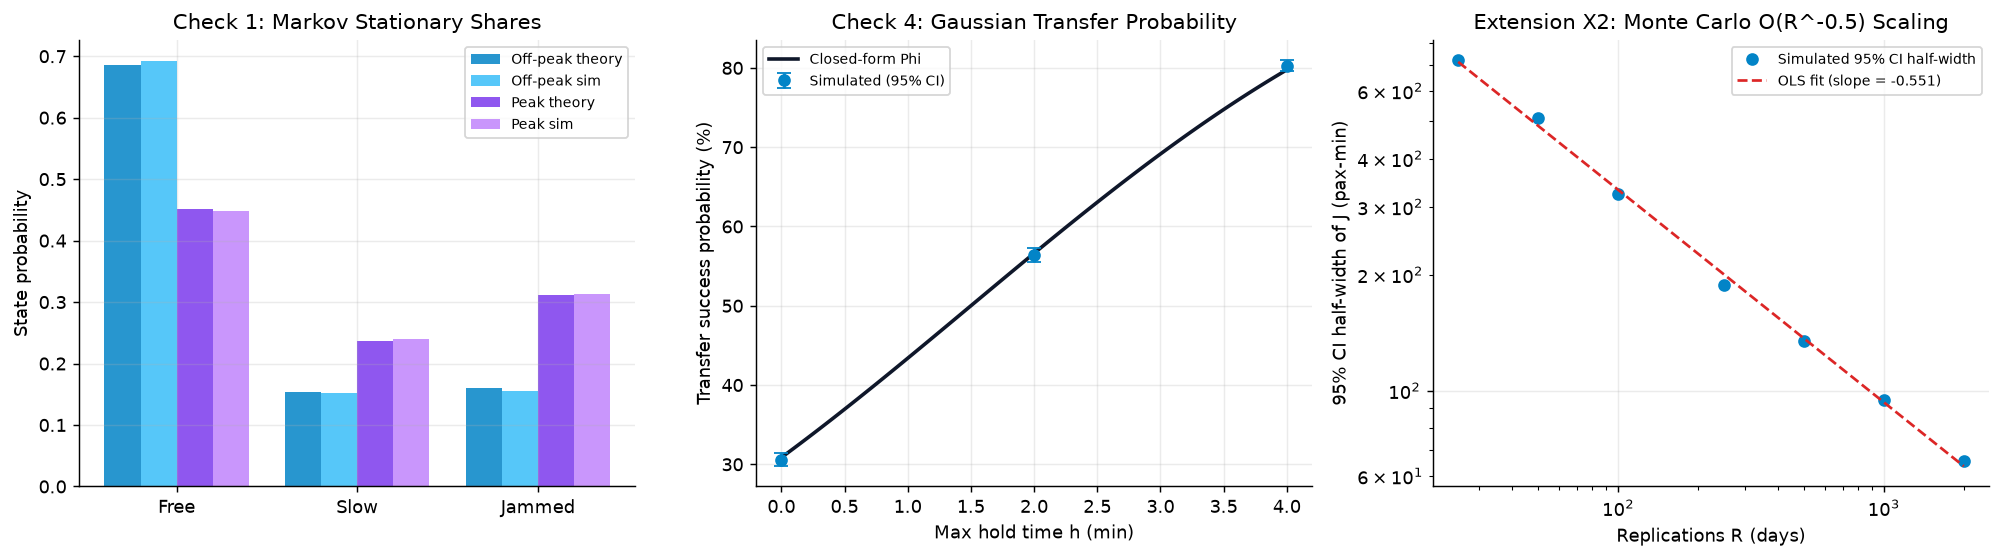

In [8]:
verify_seeds = experiment_seeds("verification", 9)
verify_rng = np.random.default_rng(verify_seeds[0])
N_VERIFY_STEPS = 50_000

sim_shares_by_regime = {}
for label, P_mat, pi_star, target_v in [
    ("off-peak", P_offpeak, pi_offpeak, target_offpeak_kmph),
    ("peak", P_peak, pi_peak, target_peak_kmph),
]:
    states = simulate_markov_chain_loop(P_mat, N_VERIFY_STEPS, verify_rng)
    sim_shares = np.bincount(states, minlength=3) / N_VERIFY_STEPS
    sim_shares_by_regime[label] = (sim_shares, pi_star)
    max_share_diff = float(np.max(np.abs(sim_shares - pi_star)))
    assert max_share_diff < 0.015, f"{label} stationary mismatch: {max_share_diff:.4f}"

    sim_mean_speed = float(np.mean(STATE_SPEEDS_KMPH[states]))
    rel_speed_err = abs(sim_mean_speed - target_v) / target_v
    assert rel_speed_err < 0.02, f"{label} speed error {rel_speed_err:.4f} >= 2%"

    print(f"PASS [Check 1 & 2 - {label:8s}]: max |sim_share - pi*| = {max_share_diff:.4f} (< 0.015), "
          f"sim_speed = {sim_mean_speed:.2f} km/h vs target {target_v:.2f} km/h (rel err {rel_speed_err:.2%})")

runtime_check_days = [precompute_day_inputs(s) for s in verify_seeds[1].spawn(80)]
for leg_name in ROUTE_LEGS_CONFIG:
    assert LEG_CAL_REL_ERRORS[leg_name] < 0.02, f"{leg_name} calibration residual {LEG_CAL_REL_ERRORS[leg_name]:.4f} >= 2%"
    sched_rt = float((leg_schedules[leg_name]["borella_sched_min"] - leg_schedules[leg_name]["origin_sched_min"]).mean())
    daily_delays = np.array([d["leg_runs"][leg_name]["borella_delay_min"].mean() for d in runtime_check_days])
    mean_delay = float(np.mean(daily_delays))
    se_delay = float(np.std(daily_delays, ddof=1) / np.sqrt(len(daily_delays)))
    se_combined = float(np.std(daily_delays, ddof=1) * np.sqrt(1.0 / len(daily_delays) + 1.0 / N_CAL_DAYS))
    rel_rt_err = abs(mean_delay) / sched_rt
    assert abs(mean_delay) <= max(0.02 * sched_rt, 2.58 * se_combined), (
        f"{leg_name} verification runtime delay {mean_delay:.2f}m outside 99% combined CI (2.58*SE_comb={2.58*se_combined:.2f}m)"
    )
    print(f"  Check 2 [{leg_name}]: cal_err={LEG_CAL_REL_ERRORS[leg_name]:.2%}, test_delay={mean_delay:+.2f} +/- {1.96*se_delay:.2f}m (rel={rel_rt_err:.2%}, 99% comb lim={2.58*se_combined:.2f}m)")
print("PASS [Check 2 - leg calibration]: all 4 legs calibrated < 2% and test delays match scheduled runtime within Monte Carlo CI.")

thinning_rng = np.random.default_rng(verify_seeds[6])
thinning_leg_cfg = {"stops": ["S0", "S1"], "base_arrival_rate_pax_per_min": [0.4, 0.0]}
N_THINNING_DAYS = 400
thinning_start_min = DAY_START_MIN
peak_minutes = sum(max(0.0, min(end, DAY_END_MIN) - max(start, thinning_start_min)) for start, end in PEAK_WINDOWS_MIN)
offpeak_minutes = (DAY_END_MIN - thinning_start_min) - peak_minutes
expected_peak = 0.4 * PEAK_ARRIVAL_MULTIPLIER * peak_minutes
expected_offpeak = 0.4 * OFFPEAK_ARRIVAL_MULTIPLIER * offpeak_minutes
peak_counts, offpeak_counts = [], []
for _ in range(N_THINNING_DAYS):
    times = [t for t, _ in generate_stop_arrivals(thinning_leg_cfg, thinning_start_min + PRE_DEPARTURE_ACCUM_MIN, thinning_rng, thinning_rng)[0]]
    n_peak = sum(1 for t in times if is_peak_time(t))
    peak_counts.append(n_peak)
    offpeak_counts.append(len(times) - n_peak)
for label, counts_arr, expected in (("peak", peak_counts, expected_peak), ("off-peak", offpeak_counts, expected_offpeak)):
    mean_count = float(np.mean(counts_arr))
    se_count = math.sqrt(expected / N_THINNING_DAYS)
    assert abs(mean_count - expected) <= 3.0 * se_count, f"Thinning {label} count {mean_count:.1f} vs {expected:.1f}"
    print(f"PASS [Check 9 - NHPP thinning, {label:8s}]: mean daily arrivals {mean_count:.1f} vs integral of lambda(t) {expected:.1f} (3 SE = {3 * se_count:.1f})")

det_feeders_df = pd.DataFrame([{"trip_id": "F1", "borella_arr_min": 500.0}])
det_conns_df = pd.DataFrame([{"trip_id": "C1", "borella_sched_min": 504.0, "borella_base_dep_min": 504.0, "borella_onboard_pax": 20}])
det_res = simulate_direction_transfers(
    det_feeders_df, det_conns_df, {"F1": "C1"}, {"F1": 10}, {"F1": 0.0},
    policy="none", hold_max_min=0.0, walk_time_min=3.5, capacity_pax=None
)
assert det_res["missed_total"] == 0 and det_res["made"] == 10, "Deterministic DES limiting case failed"
assert np.isclose(det_res["mean_wait_min"], 0.5), "Deterministic wait should equal offset - walk time"
print("PASS [Check 3 - zero-variance limit]: offset >= walk_time (uncapped) yields 0 missed transfers (P(miss) = 0.0) and wait = 0.5 min.")


def simulate_isolated_transfer_pairs(feeder_delays_min, connector_delays_min, offset_min, walk_min, policy, hold_max_min):
    n_pairs = len(feeder_delays_min)
    pair_start_min = 1000.0 * np.arange(n_pairs)
    feeder_ids = [f"F{i}" for i in range(n_pairs)]
    connector_ids = [f"C{i}" for i in range(n_pairs)]
    feeders_df = pd.DataFrame({"trip_id": feeder_ids, "borella_arr_min": pair_start_min + feeder_delays_min})
    connectors_df = pd.DataFrame({
        "trip_id": connector_ids,
        "borella_sched_min": pair_start_min + offset_min,
        "borella_base_dep_min": pair_start_min + offset_min + connector_delays_min,
        "borella_onboard_pax": 0,
    })
    res = simulate_direction_transfers(
        feeders_df, connectors_df, dict(zip(feeder_ids, connector_ids)),
        dict.fromkeys(feeder_ids, 1), dict.fromkeys(feeder_ids, 0.0),
        policy=policy, hold_max_min=hold_max_min, walk_time_min=walk_min, capacity_pax=None,
    )
    return res["made"] / n_pairs


gauss_rng = np.random.default_rng(verify_seeds[2])
N_GAUSS = 12_000
gaussian_check_rows = []
offset_min, walk_min = 4.0, 3.5
mu_f, sd_f = 2.0, 3.0
for h_val in (0.0, 2.0, 4.0):
    feeder_delays = np.array([mu_f + sd_f * sample_standard_normal_box_muller(gauss_rng) for _ in range(N_GAUSS)])
    p_sim = simulate_isolated_transfer_pairs(feeder_delays, np.zeros(N_GAUSS), offset_min, walk_min, "schedule", h_val)
    se = math.sqrt(p_sim * (1.0 - p_sim) / N_GAUSS)
    p_analytic = float(norm.cdf((offset_min + h_val - walk_min - mu_f) / sd_f))
    assert abs(p_sim - p_analytic) <= max(2.58 * se, 0.015), f"Gaussian check mismatch at h={h_val}"
    gaussian_check_rows.append({"label": f"One-sided h={h_val:.0f}m", "h": h_val, "p_sim": p_sim, "ci": 1.96 * se, "p_analytic": p_analytic})

mu_f2, sd_f2 = 12.0, 2.0
mu_c2, sd_c2 = 12.0, 2.0
offset_2, walk_2 = 5.0, 3.5
feeder_delays_2 = np.array([mu_f2 + sd_f2 * sample_standard_normal_box_muller(gauss_rng) for _ in range(N_GAUSS)])
connector_delays_2 = np.array([mu_c2 + sd_c2 * sample_standard_normal_box_muller(gauss_rng) for _ in range(N_GAUSS)])
p_sim_2 = simulate_isolated_transfer_pairs(feeder_delays_2, connector_delays_2, offset_2, walk_2, "none", 0.0)
se_2 = math.sqrt(p_sim_2 * (1.0 - p_sim_2) / N_GAUSS)
p_ana_2 = float(norm.cdf((offset_2 - walk_2 - (mu_f2 - mu_c2)) / math.sqrt(sd_f2**2 + sd_c2**2)))
assert abs(p_sim_2 - p_ana_2) <= max(2.58 * se_2, 0.015), "Two-sided Gaussian check mismatch"
gaussian_check_rows.append({"label": "Two-sided h=0m", "h": 0.0, "p_sim": p_sim_2, "ci": 1.96 * se_2, "p_analytic": p_ana_2})
gauss_df = pd.DataFrame(gaussian_check_rows)
print("PASS [Check 4 - Gaussian transfer probability (full event loop)]:")
print(gauss_df.round(4).to_string(index=False))

cons_streams = verify_seeds[3].spawn(3)
cons_traffic = generate_daily_traffic_grid(np.random.default_rng(cons_streams[0]), P_offpeak, P_peak)
cons_leg_df, cons_leg_stats = simulate_leg_day(
    "CM01_MAK_to_FOR",
    sched_cm01_mak,
    ROUTE_LEGS_CONFIG["CM01_MAK_to_FOR"],
    cons_traffic,
    np.random.default_rng(cons_streams[1]),
    np.random.default_rng(cons_streams[2]),
    capacity_pax=CAPACITY_PAX,
    alpha=LEG_ALPHAS["CM01_MAK_to_FOR"],
    return_stats=True,
)
assert cons_leg_stats["total_generated_stop_pax"] == (
    cons_leg_stats["total_boarded_pax"] + cons_leg_stats["end_of_day_unserved_pax"] + cons_leg_stats["abandoned_pax"]
)
assert cons_leg_stats["total_boarded_pax"] == cons_leg_stats["total_alighted_pax"]
assert cons_leg_stats["max_onboard_observed"] <= CAPACITY_PAX

check_day = precompute_day_inputs(verify_seeds[3])
for pol in ("none", "schedule", "realtime"):
    cons_out = evaluate_day(check_day, policy=pol, hold_max_min=3.0)
    for grp in ("A", "B"):
        g = cons_out[grp]
        accounted = g["made"] + g["missed_timing"] + g["missed_capacity"] + g["out_of_window"]
        assert accounted == g["total_generated"], f"Conservation failed for {pol} group {grp}"
        assert g["lost_timing"] <= g["missed_timing"] and g["lost_capacity"] <= g["missed_capacity"]
print("PASS [Check 5 - passenger conservation]: stop queues (boarded + unserved + abandoned) and all transfer outcomes conserved exactly.")

out_none = evaluate_day(check_day, policy="none", hold_max_min=0.0)
out_sched0 = evaluate_day(check_day, policy="schedule", hold_max_min=0.0)
out_rt0 = evaluate_day(check_day, policy="realtime", hold_max_min=0.0)
assert out_none == out_sched0 == out_rt0, "h=0 under schedule/realtime differs from none"
print("PASS [Check 6 - h=0 equivalence]: schedule(h=0) and realtime(h=0) match none identically.")

uncapped_df, uncapped_stats = simulate_leg_day(
    "CM03_KAD_to_MAK",
    sched_cm03_kad,
    ROUTE_LEGS_CONFIG["CM03_KAD_to_MAK"],
    cons_traffic,
    np.random.default_rng(cons_streams[1]),
    np.random.default_rng(cons_streams[2]),
    capacity_pax=None,
    alpha=LEG_ALPHAS["CM03_KAD_to_MAK"],
    return_stats=True,
)
assert uncapped_stats["total_left_behind_events"] == 0
uncapped_day = precompute_day_inputs(verify_seeds[3], capacity_pax=None)
uncapped_out = evaluate_day(uncapped_day, policy="schedule", hold_max_min=3.0, capacity_pax=None)
assert uncapped_out["A"]["missed_capacity"] == 0 and uncapped_out["B"]["missed_capacity"] == 0
print(f"PASS [Check 7 - capacity invariant]: capped max load = {cons_leg_stats['max_onboard_observed']} <= {CAPACITY_PAX}; uncapped produced 0 capacity misses.")

n_crn_test = 80
crn_seeds = verify_seeds[4].spawn(n_crn_test * 2)
paired_diffs, indep_diffs = [], []
for i in range(n_crn_test):
    d_a = precompute_day_inputs(crn_seeds[2 * i])
    d_b = precompute_day_inputs(crn_seeds[2 * i + 1])
    j0_a = evaluate_day(d_a, "none", 0.0)["A"]["total_cost"] + evaluate_day(d_a, "none", 0.0)["B"]["total_cost"]
    j3_a = evaluate_day(d_a, "schedule", 3.0)["A"]["total_cost"] + evaluate_day(d_a, "schedule", 3.0)["B"]["total_cost"]
    j3_b = evaluate_day(d_b, "schedule", 3.0)["A"]["total_cost"] + evaluate_day(d_b, "schedule", 3.0)["B"]["total_cost"]
    paired_diffs.append(j3_a - j0_a)
    indep_diffs.append(j3_b - j0_a)
var_paired = float(np.var(paired_diffs, ddof=1))
var_indep = float(np.var(indep_diffs, ddof=1))
assert var_paired < var_indep, f"CRN failed to reduce variance: {var_paired:.1f} >= {var_indep:.1f}"
print(f"PASS [Check 8 - CRN variance]: paired Var = {var_paired:.1f} < independent Var = {var_indep:.1f} ({100*(1 - var_paired/var_indep):.1f}% reduction).")

# Traffic states change with time, not distance, so a long journey's distance/time converges to the
# time-mean pi . v. The harmonic mean 1 / (pi . 1/v) would apply only to states indexed by distance.
journey_rng = np.random.default_rng(verify_seeds[7])
JOURNEY_TEST_LEG_KM = 20.0
for label, P_mat, pi_star in (("off-peak", P_offpeak, pi_offpeak), ("peak", P_peak, pi_peak)):
    states = simulate_markov_chain_loop(P_mat, 100_000, journey_rng)
    time_mean_kmph = float(np.dot(pi_star, STATE_SPEEDS_KMPH))
    harmonic_kmph = float(1.0 / np.dot(pi_star, 1.0 / STATE_SPEEDS_KMPH))
    long_km = 0.9 * time_mean_kmph * len(states) * TRAFFIC_STEP_MIN / 60.0
    long_speed_kmph = long_km / (travel_segment_minutes(DAY_START_MIN, long_km, states, alpha=1.0) / 60.0)
    starts_min = DAY_START_MIN + TRAFFIC_STEP_MIN * journey_rng.integers(0, len(states) - 2000, 2000)
    leg_time_min = np.mean([travel_segment_minutes(t, JOURNEY_TEST_LEG_KM, states, alpha=1.0) for t in starts_min])
    leg_speed_kmph = JOURNEY_TEST_LEG_KM / (leg_time_min / 60.0)
    assert abs(long_speed_kmph - time_mean_kmph) / time_mean_kmph < 0.01, f"{label} journey speed {long_speed_kmph:.2f} != pi.v"
    assert abs(long_speed_kmph - harmonic_kmph) / harmonic_kmph > 0.10, f"{label} journey speed indistinguishable from harmonic mean"
    assert harmonic_kmph < leg_speed_kmph <= time_mean_kmph + 0.5
    print(f"PASS [Check 10 - journey speed, {label:8s}]: long-run distance/time = {long_speed_kmph:.2f} km/h vs pi.v = {time_mean_kmph:.2f} "
          f"(harmonic mean {harmonic_kmph:.2f}); {JOURNEY_TEST_LEG_KM:.0f} km journeys average {leg_speed_kmph:.2f} km/h")

x3_days = [precompute_day_inputs(s, eta_noise_sd_min=0.0) for s in verify_seeds[8].spawn(100)]
x3_hold_saved = []
for d in x3_days:
    for h_val in (3.0, 10.0):
        rt_out = evaluate_day(d, "realtime", h_val)
        sc_out = evaluate_day(d, "schedule", h_val)
        for grp in ("A", "B"):
            assert rt_out[grp]["total_hold_pax_min"] <= sc_out[grp]["total_hold_pax_min"] + 1e-9, "Real-time held longer than schedule"
            assert rt_out[grp]["made"] == sc_out[grp]["made"], "Exact ETAs changed the number of connections made"
            x3_hold_saved.append(sc_out[grp]["total_hold_pax_min"] - rt_out[grp]["total_hold_pax_min"])
print(f"PASS [Check 11 - X3 exact-ETA limit]: with sigma = 0, real-time holding never holds longer than schedule holding and makes "
      f"the same connections on {len(x3_hold_saved)} day-direction cases (mean hold saved {np.mean(x3_hold_saved):.0f} pax-min).")

# Check 12: buses needed by the published timetable; a whole-route shift needs no extra buses.
for delta in np.arange(-30.0, 35.0, 5.0):
    for route in ROUTES:
        kw = {"shift_cm01_min": delta} if route == "CM01" else {"shift_cm03_min": delta}
        assert len(bus_blocks(route_trip_list(shifted_schedules(**kw), route))) == BASE_FLEET[route], f"{route} shift {delta} needs more buses"
print(f"PASS [Check 12 - fleet]: published timetable needs {BASE_FLEET} buses; every route shift from -30 to +30 min needs the same.")

# Check 13: the extra-bus timetable needs at most one more bus and keeps every turnaround >= the minimum.
extra_by_route = {route: best_extra_bus(leg_schedules, route) for route in ROUTES}
for route, extra in extra_by_route.items():
    blocks = bus_blocks(route_trip_list(with_extra_trips(leg_schedules, extra), route))
    layovers = [b[k + 1][3] - b[k][4] for b in blocks for k in range(len(b) - 1)]
    assert len(blocks) <= BASE_FLEET[route] + 1, f"{route} extra bus needs {len(blocks) - BASE_FLEET[route]} more buses"
    assert min(layovers) >= MIN_TURNAROUND_MIN - 1e-9
    print(f"  Check 13 [{route}]: {sum(len(df) for df in extra.values())} extra trips run on {len(blocks)} buses (base {BASE_FLEET[route]}), min turnaround {min(layovers):.0f} min")
print("PASS [Check 13 - extra bus]: each extra-bus timetable runs on at most one more bus with valid turnarounds.")

# Check 14: extra trips on Pettah->Makumbura only cannot change Kadawatha->Pettah transfers (random draws stay aligned).
d_plain = precompute_day_inputs(verify_seeds[3])
d_b_only = precompute_day_inputs(verify_seeds[3], extra_trips={"CM01_FOR_to_MAK": extra_by_route["CM01"]["CM01_FOR_to_MAK"]})
for pol, h_val in (("none", 0.0), ("realtime", 3.0)):
    assert evaluate_day(d_plain, pol, h_val)["A"] == evaluate_day(d_b_only, pol, h_val)["A"], "Extra trips changed an unrelated direction"
print("PASS [Check 14 - isolation]: extra Pettah->Makumbura trips leave Group A results identical.")

# Check 15: adding trips keeps the number of through passengers the same, so scenarios are compared on equal demand.
d_both = precompute_day_inputs(verify_seeds[3], extra_trips={**extra_by_route["CM01"], **extra_by_route["CM03"]})
for grp in ("A", "B"):
    assert evaluate_day(d_plain, "none", 0.0)[grp]["total_generated"] == evaluate_day(d_both, "none", 0.0)[grp]["total_generated"]
print("PASS [Check 15 - fixed demand]: through passengers per day are unchanged when extra trips are added.")

MAX_R_CONV = 2000
conv_seeds = verify_seeds[5].spawn(MAX_R_CONV)
PRECOMPUTED_POOL = [precompute_day_inputs(s) for s in conv_seeds]
pool_j_vals = np.array([evaluate_day(d, "realtime", 3.0)["A"]["total_cost"] + evaluate_day(d, "realtime", 3.0)["B"]["total_cost"] for d in PRECOMPUTED_POOL])
r_grid = np.array([25, 50, 100, 250, 500, 1000, 2000])
ci_halfwidths = np.array([1.96 * np.std(pool_j_vals[:r], ddof=1) / np.sqrt(r) for r in r_grid])
slope_loglog, intercept_loglog = np.polyfit(np.log10(r_grid), np.log10(ci_halfwidths), 1)
assert -0.60 <= slope_loglog <= -0.40, f"Monte Carlo scaling slope {slope_loglog:.3f} far from -0.5"
print(f"PASS [Extension X2 - MC error scaling]: log-log slope = {slope_loglog:.3f} (theoretical -0.500).")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))

ax1 = axes[0]
x_idx = np.arange(3)
w_bar = 0.2
off_sim, off_pi = sim_shares_by_regime["off-peak"]
pk_sim, pk_pi = sim_shares_by_regime["peak"]
ax1.bar(x_idx - 1.5 * w_bar, off_pi, width=w_bar, color="#0284c7", alpha=0.85, label="Off-peak theory")
ax1.bar(x_idx - 0.5 * w_bar, off_sim, width=w_bar, color="#38bdf8", alpha=0.85, label="Off-peak sim")
ax1.bar(x_idx + 0.5 * w_bar, pk_pi, width=w_bar, color="#7c3aed", alpha=0.85, label="Peak theory")
ax1.bar(x_idx + 1.5 * w_bar, pk_sim, width=w_bar, color="#c084fc", alpha=0.85, label="Peak sim")
ax1.set_xticks(x_idx)
ax1.set_xticklabels(STATE_NAMES)
ax1.set_ylabel("State probability")
ax1.set_title("Check 1: Markov Stationary Shares")
ax1.legend(fontsize=8)

ax2 = axes[1]
one_sided = gauss_df[gauss_df["label"].str.startswith("One-sided")]
h_dense = np.linspace(0.0, 4.0, 80)
p_dense = norm.cdf((4.0 + h_dense - 3.5 - 2.0) / 3.0)
ax2.plot(h_dense, 100.0 * p_dense, color="#0f172a", linewidth=2, label="Closed-form Phi")
ax2.errorbar(one_sided["h"], 100.0 * one_sided["p_sim"], yerr=100.0 * one_sided["ci"], fmt="o", color="#0284c7", capsize=4, label="Simulated (95% CI)")
ax2.set_xlabel("Max hold time h (min)")
ax2.set_ylabel("Transfer success probability (%)")
ax2.set_title("Check 4: Gaussian Transfer Probability")
ax2.legend(fontsize=8)

ax3 = axes[2]
ax3.loglog(r_grid, ci_halfwidths, "o", color="#0284c7", label="Simulated 95% CI half-width")
ax3.loglog(r_grid, 10**(intercept_loglog + slope_loglog * np.log10(r_grid)), "--", color="#dc2626", label=f"OLS fit (slope = {slope_loglog:.3f})")
ax3.set_xlabel("Replications R (days)")
ax3.set_ylabel("95% CI half-width of J (pax-min)")
ax3.set_title("Extension X2: Monte Carlo O(R^-0.5) Scaling")
ax3.legend(fontsize=8)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "verification.png", bbox_inches="tight")
plt.show()

## 5. Experiments and results

*Provenance: AI-generated.*

We conduct the following experiments using common random numbers across identical simulated days. Each experiment draws its seeds from its own named stream (`experiment_seeds`), so re-running one cell does not change any other experiment's results:

- **E1 (Baseline diagnosis, $R = 1000$):** Quantify missed timing vs missed capacity rates, mean transfer wait times, and objective cost $J(0, 0)$ on the published timetable without holding.
- **E2 (Holding sweep, $h \in [0, 10]\text{ min}$, $R = 400$):** Compare `schedule` vs `realtime` holding at the current timetable ($\Delta = 0$).
- **E3 (Timetable shift and joint optimization, $\Delta \in [-30, +30]\text{ min}$, $R = 200$):** Evaluate shifting CM01 or CM03 (both directions of the shifted route) jointly with real-time holding $h \in [0, 10]\text{ min}$ for both routes, and pick the joint optimum $(\text{route}^*, h^*, \Delta^*)$.
- **E4 (Stretch goal X3 - ETA prediction noise, $R = 500$):** Test how real-time ETA holding performs against schedule-based holding as GPS prediction error $\sigma_{\text{eta}}$ grows from $0$ to $4\text{ min}$.
- **E6 (Ticket validity, $R = 300$):** With patience and validity limits removed, how long each through-ticket passenger would have to wait at Borella to board, compared with the proposed 2-hour validity. Removing the limits keeps the result from being decided by the rule being tested.
- **Operating assumption ($R = 300$):** Repeat the baseline and the best policy with early-running connectors waiting at Borella for their timetable time, since it is not known whether Metro buses do this.
- **E7 (Current fleet vs one extra bus, $R = 1000$):** Compare the baseline, the best shift with real-time holding, the same with a Borella timing point, one extra CM01 or CM03 bus, and the timing-point policy plus the better extra bus. Report missed connections, the share of through passengers served by Metro, $J$, and the share of late terminal turnarounds, then print the recommended fixed timetable for the current fleet.
- **E5 & Extensions X5/X6:** Isolate the capacity bottleneck ($C=80$ vs $C=\infty$), run a multi-parameter sensitivity tornado on missed transfers and cost per passenger with 95% CIs plus a 2D grid analysis, and benchmark vectorized vs loop Markov traffic generation.

=== E1: Current Timetable Baseline Diagnosis (R = 1000 CRN days, 95% CI) ===
    Miss A (%)     Miss B (%)   Miss All (%)  Timing Miss (%)  Cap Miss (%)       Lost (%)  Wait p95 (min) Mean Wait (min)      J (pax-min)
21.78 +/- 0.95 10.81 +/- 0.65 15.39 +/- 0.55             12.9          2.49 10.30 +/- 0.47            85.5  37.69 +/- 0.37 10261.1 +/- 93.8



=== E2: Borella Holding Sweep at Current Timetable (R = 400 CRN days) ===
 h_min  sched_miss_A  sched_miss_B  sched_miss_all  sched_hold_cost  sched_J  rt_miss_all  rt_hold_cost     rt_J
   0.0         21.45         10.08           14.88             0.00 10291.37        14.88          0.00 10291.37
   1.0         19.41          9.48           13.65            69.89 10223.82        14.12          3.89 10209.54
   2.0         18.58          9.16           13.13           134.73 10231.24        13.27         12.98 10119.34
   3.0         17.24          8.61           12.26           194.57 10195.79        12.58         24.25 10053.48
   4.0         16.00          8.24           11.53           249.78 10171.29        11.80         38.28  9979.99
   5.0         14.94          7.68           10.75           300.61 10139.71        11.05         55.29  9915.32
   6.0         14.13          7.29           10.17           347.58 10120.75        10.50         72.55  9872.22
   7.0         13.33 

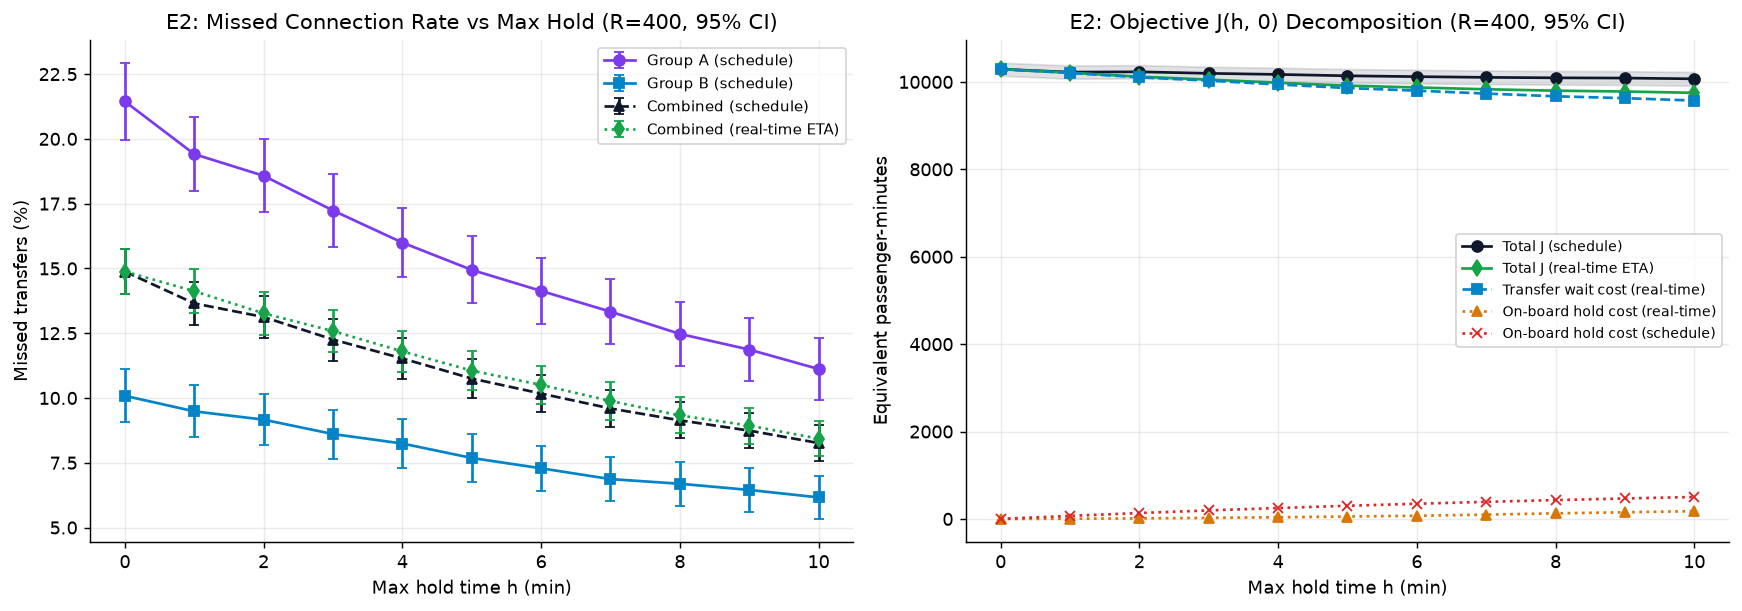

In [9]:
def summarize_ci(values):
    # Mean and normal-approximation 95% CI half-width over replications.
    arr = np.asarray(values, dtype=float)
    mean_val = float(np.mean(arr))
    ci_half = 1.96 * float(np.std(arr, ddof=1)) / np.sqrt(len(arr))
    return mean_val, ci_half


def evaluate_policy_over_days(days_pool, policy, hold_max_min, walk_time_min=WALK_TIME_PLACEHOLDER_MIN, capacity_pax=CAPACITY_PAX, wait_weight=WAIT_WEIGHT, hold_weight=HOLD_WEIGHT, ticket_validity_min=TICKET_VALIDITY_MIN):
    miss_a, miss_b, miss_all = [], [], []
    lost_all, boarded_waits = [], []
    miss_timing_all, miss_cap_all = [], []
    wait_min_all, j_all, wait_cost_all, hold_cost_all = [], [], [], []
    j_per_pax_all = []
    served_all = []

    for day_in in days_pool:
        res = evaluate_day(
            day_in,
            policy=policy,
            hold_max_min=hold_max_min,
            walk_time_min=walk_time_min,
            capacity_pax=capacity_pax,
            wait_weight=wait_weight,
            hold_weight=hold_weight,
            ticket_validity_min=ticket_validity_min,
        )
        a_in = max(1, res["A"]["in_window_total"])
        b_in = max(1, res["B"]["in_window_total"])
        tot_in = max(1, res["A"]["in_window_total"] + res["B"]["in_window_total"])

        miss_a.append(100.0 * res["A"]["missed_total"] / a_in)
        miss_b.append(100.0 * res["B"]["missed_total"] / b_in)
        miss_timing_all.append(100.0 * (res["A"]["missed_timing"] + res["B"]["missed_timing"]) / tot_in)
        miss_cap_all.append(100.0 * (res["A"]["missed_capacity"] + res["B"]["missed_capacity"]) / tot_in)
        miss_all.append(100.0 * (res["A"]["missed_total"] + res["B"]["missed_total"]) / tot_in)
        wait_min_all.append((res["A"]["total_wait_min"] + res["B"]["total_wait_min"]) / tot_in)
        wait_cost_all.append(res["A"]["wait_cost"] + res["B"]["wait_cost"])
        hold_cost_all.append(res["A"]["hold_cost"] + res["B"]["hold_cost"])
        j_all.append(res["A"]["total_cost"] + res["B"]["total_cost"])
        j_per_pax_all.append((res["A"]["total_cost"] + res["B"]["total_cost"]) / max(1, res["A"]["total_generated"] + res["B"]["total_generated"]))
        lost_all.append(100.0 * (res["A"]["lost_total"] + res["B"]["lost_total"]) / tot_in)
        # Served = boarded a Metro connector (first or later bus), out of all through passengers that day.
        boarded = sum(res[g]["made"] + res[g]["missed_total"] - res[g]["lost_total"] for g in ("A", "B"))
        served_all.append(100.0 * boarded / max(1, res["A"]["total_generated"] + res["B"]["total_generated"]))
        boarded_waits.extend(res["A"]["boarded_wait_mins"])
        boarded_waits.extend(res["B"]["boarded_wait_mins"])

    ma_m, ma_ci = summarize_ci(miss_a)
    mb_m, mb_ci = summarize_ci(miss_b)
    mall_m, mall_ci = summarize_ci(miss_all)
    mt_m, _ = summarize_ci(miss_timing_all)
    mc_m, _ = summarize_ci(miss_cap_all)
    wm_m, wm_ci = summarize_ci(wait_min_all)
    wc_m, _ = summarize_ci(wait_cost_all)
    hc_m, _ = summarize_ci(hold_cost_all)
    j_m, j_ci = summarize_ci(j_all)
    jpp_m, jpp_ci = summarize_ci(j_per_pax_all)
    lost_m, lost_ci = summarize_ci(lost_all)
    served_m, served_ci = summarize_ci(served_all)
    waits_arr = np.asarray(boarded_waits, dtype=float)
    return {
        "miss_A_pct": ma_m, "miss_A_ci": ma_ci,
        "miss_B_pct": mb_m, "miss_B_ci": mb_ci,
        "miss_all_pct": mall_m, "miss_all_ci": mall_ci,
        "miss_timing_pct": mt_m, "miss_cap_pct": mc_m,
        "mean_wait_min": wm_m, "mean_wait_ci": wm_ci,
        "wait_cost": wc_m, "hold_cost": hc_m,
        "J_mean": j_m, "J_ci": j_ci,
        "J_per_pax": jpp_m, "J_per_pax_ci": jpp_ci,
        "lost_pct": lost_m, "lost_ci": lost_ci,
        "served_pct": served_m, "served_ci": served_ci,
        "wait_p95_min": float(np.percentile(waits_arr, 95)) if waits_arr.size else float("nan"),
        "boarded_waits": waits_arr,
    }


R_FINAL = 1000  # days
FINAL_POOL = PRECOMPUTED_POOL[:R_FINAL]
base_summary = evaluate_policy_over_days(FINAL_POOL, "none", 0.0)

print(f"=== E1: Current Timetable Baseline Diagnosis (R = {R_FINAL} CRN days, 95% CI) ===")
e1_table = pd.DataFrame([{
    "Miss A (%)": f"{base_summary['miss_A_pct']:.2f} +/- {base_summary['miss_A_ci']:.2f}",
    "Miss B (%)": f"{base_summary['miss_B_pct']:.2f} +/- {base_summary['miss_B_ci']:.2f}",
    "Miss All (%)": f"{base_summary['miss_all_pct']:.2f} +/- {base_summary['miss_all_ci']:.2f}",
    "Timing Miss (%)": round(base_summary["miss_timing_pct"], 2),
    "Cap Miss (%)": round(base_summary["miss_cap_pct"], 2),
    "Lost (%)": f"{base_summary['lost_pct']:.2f} +/- {base_summary['lost_ci']:.2f}",
    "Wait p95 (min)": round(base_summary["wait_p95_min"], 1),
    "Mean Wait (min)": f"{base_summary['mean_wait_min']:.2f} +/- {base_summary['mean_wait_ci']:.2f}",
    "J (pax-min)": f"{base_summary['J_mean']:.1f} +/- {base_summary['J_ci']:.1f}",
}])
print(e1_table.to_string(index=False))

R_SWEEP = 400  # days
SWEEP_POOL = PRECOMPUTED_POOL[:R_SWEEP]
HOLD_GRID_MIN = np.arange(0.0, 11.0, 1.0)

e2_rows = []
for h_val in HOLD_GRID_MIN:
    pol_s = "none" if h_val == 0.0 else "schedule"
    pol_r = "none" if h_val == 0.0 else "realtime"
    s_res = evaluate_policy_over_days(SWEEP_POOL, pol_s, float(h_val))
    r_res = evaluate_policy_over_days(SWEEP_POOL, pol_r, float(h_val))
    e2_rows.append({
        "h_min": float(h_val),
        "sched_miss_A": s_res["miss_A_pct"], "sched_miss_A_ci": s_res["miss_A_ci"],
        "sched_miss_B": s_res["miss_B_pct"], "sched_miss_B_ci": s_res["miss_B_ci"],
        "sched_miss_all": s_res["miss_all_pct"], "sched_miss_all_ci": s_res["miss_all_ci"],
        "sched_wait_cost": s_res["wait_cost"], "sched_hold_cost": s_res["hold_cost"],
        "sched_J": s_res["J_mean"], "sched_J_ci": s_res["J_ci"],
        "rt_miss_all": r_res["miss_all_pct"], "rt_miss_all_ci": r_res["miss_all_ci"],
        "rt_wait_cost": r_res["wait_cost"], "rt_hold_cost": r_res["hold_cost"],
        "rt_J": r_res["J_mean"], "rt_J_ci": r_res["J_ci"],
    })

e2_df = pd.DataFrame(e2_rows)
print(f"\n=== E2: Borella Holding Sweep at Current Timetable (R = {R_SWEEP} CRN days) ===")
print(e2_df[["h_min", "sched_miss_A", "sched_miss_B", "sched_miss_all", "sched_hold_cost", "sched_J", "rt_miss_all", "rt_hold_cost", "rt_J"]].round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

ax1 = axes[0]
ax1.errorbar(e2_df["h_min"], e2_df["sched_miss_A"], yerr=e2_df["sched_miss_A_ci"], marker="o", capsize=3, color="#7c3aed", label="Group A (schedule)")
ax1.errorbar(e2_df["h_min"], e2_df["sched_miss_B"], yerr=e2_df["sched_miss_B_ci"], marker="s", capsize=3, color="#0284c7", label="Group B (schedule)")
ax1.errorbar(e2_df["h_min"], e2_df["sched_miss_all"], yerr=e2_df["sched_miss_all_ci"], marker="^", linestyle="--", capsize=3, color="#0f172a", label="Combined (schedule)")
ax1.errorbar(e2_df["h_min"], e2_df["rt_miss_all"], yerr=e2_df["rt_miss_all_ci"], marker="d", linestyle=":", capsize=3, color="#16a34a", label="Combined (real-time ETA)")
ax1.set_xlabel("Max hold time h (min)")
ax1.set_ylabel("Missed transfers (%)")
ax1.set_title(f"E2: Missed Connection Rate vs Max Hold (R={R_SWEEP}, 95% CI)")
ax1.legend(fontsize=8.5)

ax2 = axes[1]
ax2.plot(e2_df["h_min"], e2_df["sched_J"], marker="o", color="#0f172a", label="Total J (schedule)")
ax2.fill_between(e2_df["h_min"], e2_df["sched_J"] - e2_df["sched_J_ci"], e2_df["sched_J"] + e2_df["sched_J_ci"], color="#0f172a", alpha=0.12)
ax2.plot(e2_df["h_min"], e2_df["rt_J"], marker="d", color="#16a34a", label="Total J (real-time ETA)")
ax2.plot(e2_df["h_min"], e2_df["rt_wait_cost"], marker="s", linestyle="--", color="#0284c7", label="Transfer wait cost (real-time)")
ax2.plot(e2_df["h_min"], e2_df["rt_hold_cost"], marker="^", linestyle=":", color="#d97706", label="On-board hold cost (real-time)")
ax2.plot(e2_df["h_min"], e2_df["sched_hold_cost"], marker="x", linestyle=":", color="#dc2626", label="On-board hold cost (schedule)")
ax2.set_xlabel("Max hold time h (min)")
ax2.set_ylabel("Equivalent passenger-minutes")
ax2.set_title(f"E2: Objective J(h, 0) Decomposition (R={R_SWEEP}, 95% CI)")
ax2.legend(fontsize=8)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "holding_sweep.png", bbox_inches="tight")
plt.show()

Best joint policy per shifted route (realtime holding):
route  delta_min  h_min  miss_A_pct  miss_B_pct  miss_all_pct  J_mean   J_ci
 CM01       10.0   10.0       10.43       11.44         11.09 9306.81 216.56
 CM03      -10.0   10.0       10.22       12.60         11.60 9323.23 219.95

=== E3: Top 8 Joint (CM01 Shift Delta, Real-Time Hold h) Policies (R = 200) ===
 delta_min  h_min  miss_A_pct  miss_B_pct  miss_all_pct  J_mean   J_ci
      10.0   10.0       10.43       11.44         11.09 9306.81 216.56
      15.0   10.0        7.59        9.91          8.88 9307.77 209.62
      10.0    8.0       11.46       12.31         12.04 9357.87 215.33
      15.0    8.0        8.49       11.39         10.12 9381.02 217.51
       5.0   10.0       13.68        8.61         10.81 9405.88 225.03
      10.0    6.0       12.66       13.57         13.27 9429.87 219.35
      10.0    5.0       13.14       14.21         13.84 9466.23 221.98
       5.0    8.0       15.45        9.37         11.97 9467.30 

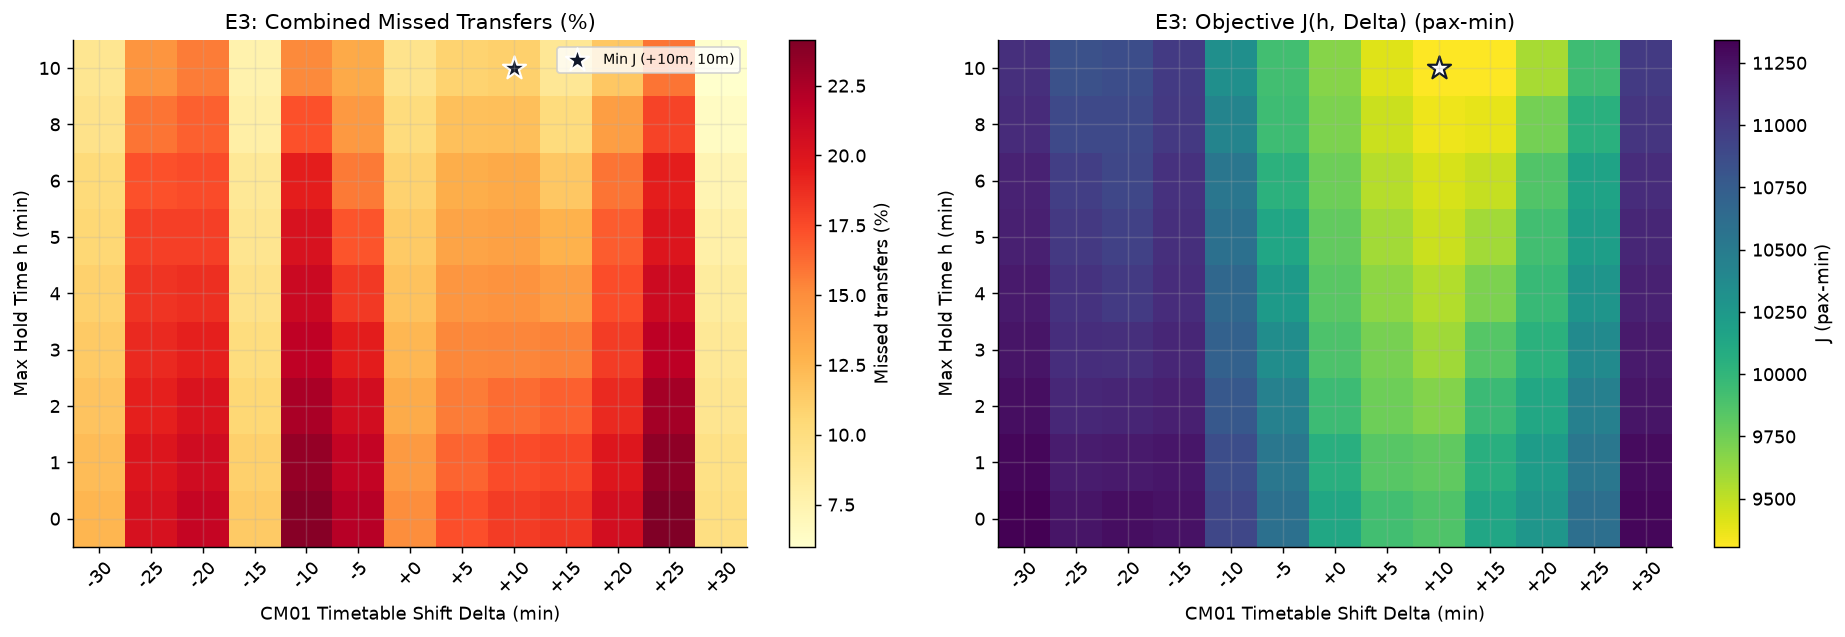


=== E4: Real-Time ETA Holding vs Schedule Holding at Optimal Shift (Delta=+10m, h=10.0m, R=500) ===
           policy_mode  eta_noise_sd_min  miss_all_pct  hold_cost_pax_min  J_mean   J_ci
schedule (no ETA skip)               0.0         10.65             609.22 9756.37 130.53
  realtime ETA holding               0.0         10.68             208.85 9332.92 124.70
  realtime ETA holding               1.0         10.91             208.36 9355.15 125.38
  realtime ETA holding               2.0         11.18             209.21 9390.19 126.70
  realtime ETA holding               4.0         11.77             213.95 9461.46 129.00



=== Consolidated Policy Comparison (R = 1000 CRN days, 95% CI) ===
                    Scenario     Miss A (%)     Miss B (%)   Miss All (%)       Lost (%) Mean Wait (min)  Wait p95 (min)  Hold Cost      J (pax-min)
    Baseline (current, none) 21.99 +/- 0.98 10.07 +/- 0.64 15.05 +/- 0.56  9.87 +/- 0.46  37.65 +/- 0.38            85.9        0.0 10255.9 +/- 94.1
  Hold only (schedule, h=3m) 17.58 +/- 0.92  8.85 +/- 0.61 12.48 +/- 0.52  7.43 +/- 0.40  36.18 +/- 0.38            85.3      196.3 10171.3 +/- 94.2
  Hold only (realtime, h=3m) 18.01 +/- 0.92  8.99 +/- 0.61 12.75 +/- 0.53  7.66 +/- 0.40  36.28 +/- 0.38            85.4       21.9 10015.9 +/- 92.7
      Shift only (CM01 +10m) 16.54 +/- 0.85 20.64 +/- 0.84 18.91 +/- 0.61 11.04 +/- 0.47  36.55 +/- 0.38            80.3        0.0 10048.8 +/- 94.9
Joint schedule (h=10m, +10m)  9.32 +/- 0.69 11.82 +/- 0.69 10.76 +/- 0.49  4.04 +/- 0.30  32.03 +/- 0.39            79.0      597.8  9781.9 +/- 96.5
Joint realtime (h=10m, +10m)  9.50 +/-

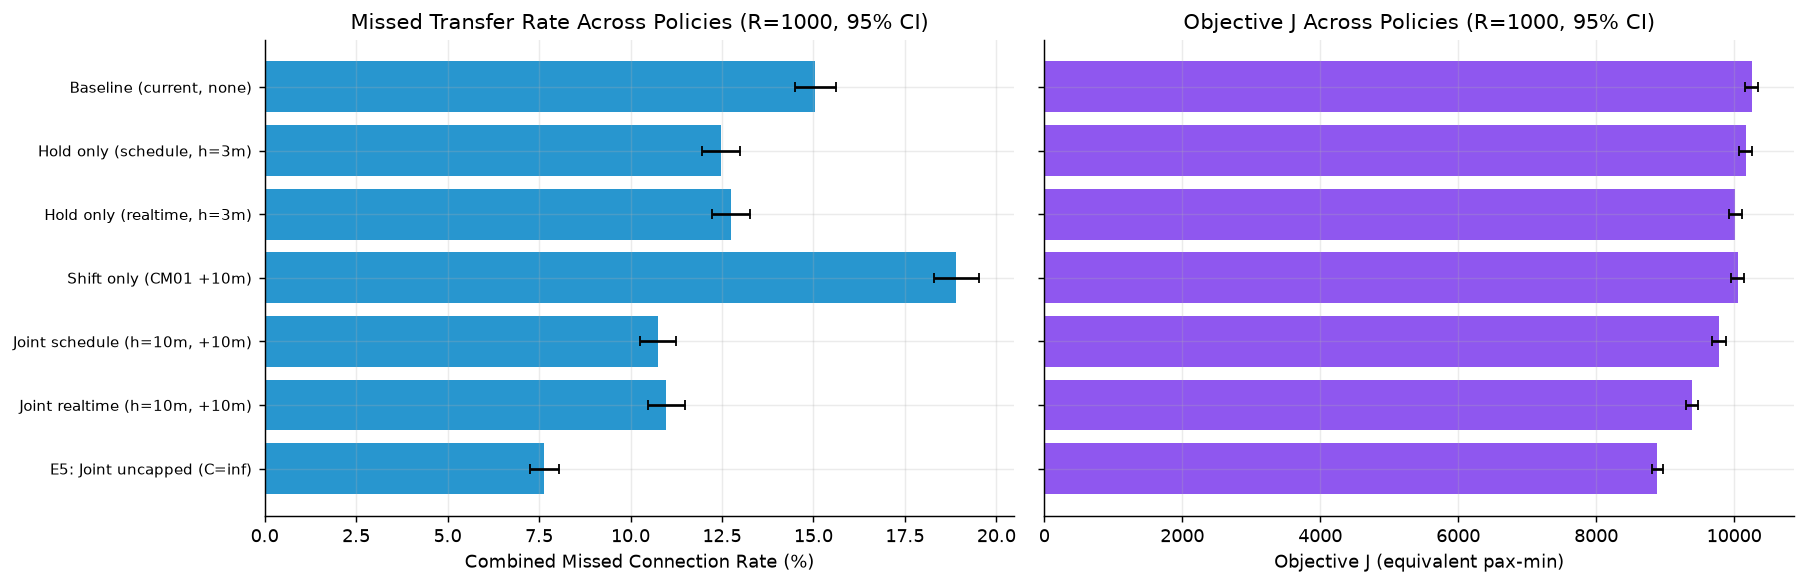

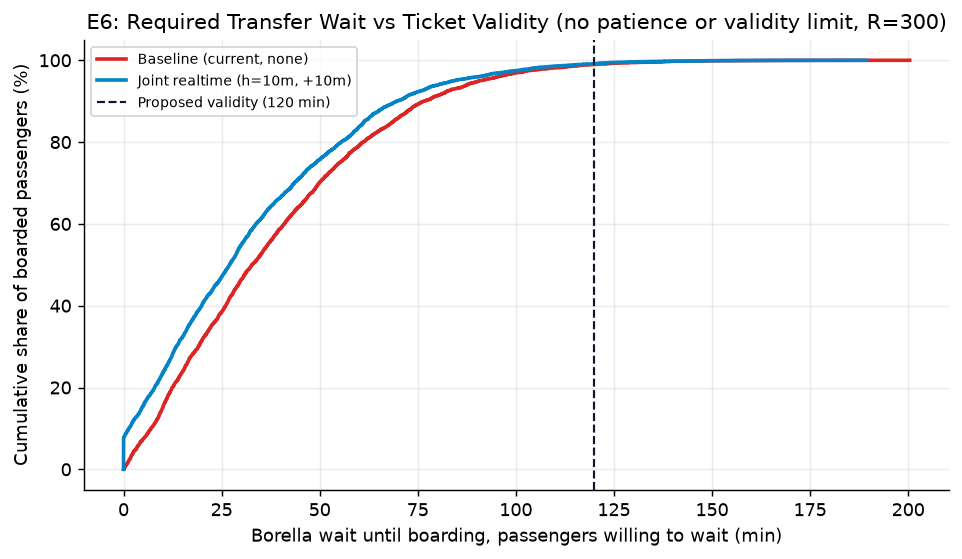


=== E6: Wait Each Through-Ticket Passenger Would Need, With No Patience or Validity Limit (R = 300) ===
                    Scenario  Median wait (min)  p90 wait (min)  p95 wait (min)  Max wait (min)  Boarded within 120 min (%) No later bus that day (%)
    Baseline (current, none)               32.8            76.6            90.7           200.4                       98.99             2.23 +/- 0.36
Joint realtime (h=10m, +10m)               27.0            69.7            84.3           189.4                       99.12             0.84 +/- 0.23



=== Operating assumption: do early-running connectors wait at Borella for their timetable time? (R = 300) ===
                    Scenario Early connectors wait for timetable   Miss All (%)  Miss A (%)  Miss B (%)       J (pax-min)
    Baseline (current, none)                     no (main model) 15.06 +/- 1.05       20.78       10.97 10405.5 +/- 170.7
    Baseline (current, none)                                 yes  6.66 +/- 0.76        8.70        5.22 15982.7 +/- 214.6
Joint realtime (h=10m, +10m)                     no (main model) 10.99 +/- 0.96        9.18       12.31  9474.2 +/- 168.1
Joint realtime (h=10m, +10m)                                 yes  5.22 +/- 0.69        4.15        6.04 15332.5 +/- 212.4


In [10]:
R_GRID = 200  # days per (route, shift) cell; holds are evaluated on the same days
SHIFT_VALUES_MIN = np.arange(-30.0, 35.0, 5.0)
HOLD_GRID_COARSE_MIN = np.array([0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0])
SHIFT_ROUTES = ("CM01", "CM03")
grid_seeds = experiment_seeds("e3_grid", R_GRID)


def shift_kwargs(route, delta_min):
    return {"shift_cm01_min": float(delta_min)} if route == "CM01" else {"shift_cm03_min": float(delta_min)}


all_grid_records = []
for delta in SHIFT_VALUES_MIN:
    for route in SHIFT_ROUTES:
        days_delta = [precompute_day_inputs(s, **shift_kwargs(route, delta)) for s in grid_seeds]
        for h_val in HOLD_GRID_COARSE_MIN:
            pol = "none" if h_val == 0.0 else "realtime"
            res = evaluate_policy_over_days(days_delta, pol, float(h_val))
            all_grid_records.append({
                "route": route,
                "delta_min": float(delta),
                "h_min": float(h_val),
                "miss_A_pct": res["miss_A_pct"],
                "miss_B_pct": res["miss_B_pct"],
                "miss_all_pct": res["miss_all_pct"],
                "J_mean": res["J_mean"],
                "J_ci": res["J_ci"],
            })

all_grid_df = pd.DataFrame(all_grid_records)
best_by_route = all_grid_df.loc[all_grid_df.groupby("route")["J_mean"].idxmin()]
print("Best joint policy per shifted route (realtime holding):")
print(best_by_route.round(2).to_string(index=False))
shift_target_route = str(best_by_route.sort_values("J_mean").iloc[0]["route"])

grid_records = all_grid_df[all_grid_df["route"] == shift_target_route].drop(columns="route").to_dict("records")
miss_grid = np.zeros((len(HOLD_GRID_COARSE_MIN), len(SHIFT_VALUES_MIN)))
j_grid = np.zeros((len(HOLD_GRID_COARSE_MIN), len(SHIFT_VALUES_MIN)))
for rec in grid_records:
    r_idx = int(np.where(HOLD_GRID_COARSE_MIN == rec["h_min"])[0][0])
    c_idx = int(np.where(SHIFT_VALUES_MIN == rec["delta_min"])[0][0])
    miss_grid[r_idx, c_idx] = rec["miss_all_pct"]
    j_grid[r_idx, c_idx] = rec["J_mean"]

grid_df = pd.DataFrame(grid_records)
opt_idx = int(grid_df["J_mean"].idxmin())
OPT_DELTA_MIN = float(grid_df.loc[opt_idx, "delta_min"])
OPT_H_MIN = float(grid_df.loc[opt_idx, "h_min"])

print(f"\n=== E3: Top 8 Joint ({shift_target_route} Shift Delta, Real-Time Hold h) Policies (R = {R_GRID}) ===")
print(grid_df.sort_values("J_mean").head(8).round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.0))
opt_r = int(np.where(HOLD_GRID_COARSE_MIN == OPT_H_MIN)[0][0])
opt_c = int(np.where(SHIFT_VALUES_MIN == OPT_DELTA_MIN)[0][0])

im1 = axes[0].imshow(miss_grid, aspect="auto", origin="lower", cmap="YlOrRd")
axes[0].set_xticks(range(len(SHIFT_VALUES_MIN)))
axes[0].set_xticklabels([f"{int(d):+d}" for d in SHIFT_VALUES_MIN], rotation=45)
axes[0].set_yticks(range(len(HOLD_GRID_COARSE_MIN)))
axes[0].set_yticklabels([f"{h:.0f}" for h in HOLD_GRID_COARSE_MIN])
axes[0].set_xlabel(f"{shift_target_route} Timetable Shift Delta (min)")
axes[0].set_ylabel("Max Hold Time h (min)")
axes[0].set_title("E3: Combined Missed Transfers (%)")
axes[0].scatter([opt_c], [opt_r], marker="*", s=180, color="#0f172a", edgecolor="#ffffff", linewidth=1.2, label=f"Min J ({OPT_DELTA_MIN:+.0f}m, {OPT_H_MIN:.0f}m)")
axes[0].legend(loc="upper right", fontsize=8)
plt.colorbar(im1, ax=axes[0], label="Missed transfers (%)")

im2 = axes[1].imshow(j_grid, aspect="auto", origin="lower", cmap="viridis_r")
axes[1].set_xticks(range(len(SHIFT_VALUES_MIN)))
axes[1].set_xticklabels([f"{int(d):+d}" for d in SHIFT_VALUES_MIN], rotation=45)
axes[1].set_yticks(range(len(HOLD_GRID_COARSE_MIN)))
axes[1].set_yticklabels([f"{h:.0f}" for h in HOLD_GRID_COARSE_MIN])
axes[1].set_xlabel(f"{shift_target_route} Timetable Shift Delta (min)")
axes[1].set_ylabel("Max Hold Time h (min)")
axes[1].set_title("E3: Objective J(h, Delta) (pax-min)")
axes[1].scatter([opt_c], [opt_r], marker="*", s=180, color="#ffffff", edgecolor="#0f172a", linewidth=1.2)
plt.colorbar(im2, ax=axes[1], label="J (pax-min)")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "timetable_shift_heatmap.png", bbox_inches="tight")
plt.show()

R_E4 = 500  # days
e4_seeds = experiment_seeds("e4_eta", R_E4)
opt_shift_kw = {"shift_cm03_min": OPT_DELTA_MIN} if shift_target_route == "CM03" else {"shift_cm01_min": OPT_DELTA_MIN}
e4_rows = []
days_opt_base = [precompute_day_inputs(s, **opt_shift_kw, eta_noise_sd_min=0.0) for s in e4_seeds]
sched_opt_eval = evaluate_policy_over_days(days_opt_base, "schedule", max(1.0, OPT_H_MIN))
e4_rows.append({
    "policy_mode": "schedule (no ETA skip)",
    "eta_noise_sd_min": 0.0,
    "miss_all_pct": sched_opt_eval["miss_all_pct"],
    "hold_cost_pax_min": sched_opt_eval["hold_cost"],
    "J_mean": sched_opt_eval["J_mean"],
    "J_ci": sched_opt_eval["J_ci"],
})
for sigma_eta in (0.0, 1.0, 2.0, 4.0):
    days_rt = [precompute_day_inputs(s, **opt_shift_kw, eta_noise_sd_min=sigma_eta) for s in e4_seeds]
    rt_eval = evaluate_policy_over_days(days_rt, "realtime", max(1.0, OPT_H_MIN))
    e4_rows.append({
        "policy_mode": "realtime ETA holding",
        "eta_noise_sd_min": sigma_eta,
        "miss_all_pct": rt_eval["miss_all_pct"],
        "hold_cost_pax_min": rt_eval["hold_cost"],
        "J_mean": rt_eval["J_mean"],
        "J_ci": rt_eval["J_ci"],
    })
print(f"\n=== E4: Real-Time ETA Holding vs Schedule Holding at Optimal Shift (Delta={OPT_DELTA_MIN:+.0f}m, h={max(1.0, OPT_H_MIN):.1f}m, R={R_E4}) ===")
print(pd.DataFrame(e4_rows).round(2).to_string(index=False))

final_seeds = experiment_seeds("final_comparison", R_FINAL)
final_opt_days = [precompute_day_inputs(s, **opt_shift_kw) for s in final_seeds]
final_uncapped_days = [precompute_day_inputs(s, **opt_shift_kw, capacity_pax=None) for s in final_seeds]
final_base_days = [precompute_day_inputs(s) for s in final_seeds]

policy_specs = [
    ("Baseline (current, none)", final_base_days, "none", 0.0, CAPACITY_PAX),
    ("Hold only (schedule, h=3m)", final_base_days, "schedule", 3.0, CAPACITY_PAX),
    ("Hold only (realtime, h=3m)", final_base_days, "realtime", 3.0, CAPACITY_PAX),
    (f"Shift only ({shift_target_route} {OPT_DELTA_MIN:+.0f}m)", final_opt_days, "none", 0.0, CAPACITY_PAX),
    (f"Joint schedule (h={OPT_H_MIN:.0f}m, {OPT_DELTA_MIN:+.0f}m)", final_opt_days, "none" if OPT_H_MIN == 0 else "schedule", OPT_H_MIN, CAPACITY_PAX),
    (f"Joint realtime (h={OPT_H_MIN:.0f}m, {OPT_DELTA_MIN:+.0f}m)", final_opt_days, "none" if OPT_H_MIN == 0 else "realtime", OPT_H_MIN, CAPACITY_PAX),
    (f"E5: Joint uncapped (C=inf)", final_uncapped_days, "none" if OPT_H_MIN == 0 else "realtime", OPT_H_MIN, None),
]

final_rows = []
scenario_waits = {}
for label, pool, pol, h_v, cap in policy_specs:
    s = evaluate_policy_over_days(pool, pol, h_v, capacity_pax=cap)
    final_rows.append({
        "Scenario": label,
        "Miss A (%)": f"{s['miss_A_pct']:.2f} +/- {s['miss_A_ci']:.2f}",
        "Miss B (%)": f"{s['miss_B_pct']:.2f} +/- {s['miss_B_ci']:.2f}",
        "Miss All (%)": f"{s['miss_all_pct']:.2f} +/- {s['miss_all_ci']:.2f}",
        "Mean Wait (min)": f"{s['mean_wait_min']:.2f} +/- {s['mean_wait_ci']:.2f}",
        "Hold Cost": round(s["hold_cost"], 1),
        "Lost (%)": f"{s['lost_pct']:.2f} +/- {s['lost_ci']:.2f}",
        "Wait p95 (min)": round(s["wait_p95_min"], 1),
        "J (pax-min)": f"{s['J_mean']:.1f} +/- {s['J_ci']:.1f}",
        "_miss_val": s["miss_all_pct"],
        "_miss_ci": s["miss_all_ci"],
        "_j_val": s["J_mean"],
        "_j_ci": s["J_ci"],
    })
    scenario_waits[label] = s["boarded_waits"]

final_comp_df = pd.DataFrame(final_rows)
print(f"\n=== Consolidated Policy Comparison (R = {R_FINAL} CRN days, 95% CI) ===")
print(final_comp_df[["Scenario", "Miss A (%)", "Miss B (%)", "Miss All (%)", "Lost (%)", "Mean Wait (min)", "Wait p95 (min)", "Hold Cost", "J (pax-min)"]].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14.0, 4.6))
y_pos = np.arange(len(final_comp_df))
axes[0].barh(y_pos, final_comp_df["_miss_val"], xerr=final_comp_df["_miss_ci"], color="#0284c7", alpha=0.85, capsize=3)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(final_comp_df["Scenario"], fontsize=8.5)
axes[0].invert_yaxis()
axes[0].set_xlabel("Combined Missed Connection Rate (%)")
axes[0].set_title(f"Missed Transfer Rate Across Policies (R={R_FINAL}, 95% CI)")

axes[1].barh(y_pos, final_comp_df["_j_val"], xerr=final_comp_df["_j_ci"], color="#7c3aed", alpha=0.85, capsize=3)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([])
axes[1].invert_yaxis()
axes[1].set_xlabel("Objective J (equivalent pax-min)")
axes[1].set_title(f"Objective J Across Policies (R={R_FINAL}, 95% CI)")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "policy_comparison.png", bbox_inches="tight")
plt.show()


R_E6 = 300  # days
UNLIMITED_MIN = 1.0e9  # min, removes the patience and validity limits
e6_seeds = final_seeds[:R_E6]
validity_specs = [
    ("Baseline (current, none)", {}, "none", 0.0, "#dc2626"),
    (policy_specs[5][0], opt_shift_kw, policy_specs[5][2], OPT_H_MIN, "#0284c7"),
]
validity_rows = []
fig, ax = plt.subplots(figsize=(7.5, 4.4))
for scenario_label, scenario_shift_kw, pol, h_v, line_color in validity_specs:
    unlimited_days = [precompute_day_inputs(s, **scenario_shift_kw, patience_min=UNLIMITED_MIN) for s in e6_seeds]
    unlimited = evaluate_policy_over_days(unlimited_days, pol, h_v, ticket_validity_min=UNLIMITED_MIN)
    waits = np.sort(unlimited["boarded_waits"])
    ax.plot(waits, 100.0 * np.arange(1, len(waits) + 1) / len(waits), color=line_color, linewidth=2, label=scenario_label)
    validity_rows.append({
        "Scenario": scenario_label,
        "Median wait (min)": round(float(np.median(waits)), 1),
        "p90 wait (min)": round(float(np.percentile(waits, 90)), 1),
        "p95 wait (min)": round(float(np.percentile(waits, 95)), 1),
        "Max wait (min)": round(float(np.max(waits)), 1),
        f"Boarded within {TICKET_VALIDITY_MIN:.0f} min (%)": round(100.0 * float(np.mean(waits <= TICKET_VALIDITY_MIN)), 2),
        "No later bus that day (%)": f"{unlimited['lost_pct']:.2f} +/- {unlimited['lost_ci']:.2f}",
    })
ax.axvline(TICKET_VALIDITY_MIN, color="#0f172a", linestyle="--", linewidth=1.2, label=f"Proposed validity ({TICKET_VALIDITY_MIN:.0f} min)")
ax.set_xlabel("Borella wait until boarding, passengers willing to wait (min)")
ax.set_ylabel("Cumulative share of boarded passengers (%)")
ax.set_title(f"E6: Required Transfer Wait vs Ticket Validity (no patience or validity limit, R={R_E6})")
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "ticket_validity.png", bbox_inches="tight")
plt.show()

print(f"\n=== E6: Wait Each Through-Ticket Passenger Would Need, With No Patience or Validity Limit (R = {R_E6}) ===")
print(pd.DataFrame(validity_rows).to_string(index=False))

R_OPS = 300  # days
ops_seeds = final_seeds[:R_OPS]
ops_rows = []
for scenario_label, scenario_shift_kw, pol, h_v in (
    ("Baseline (current, none)", {}, "none", 0.0),
    (policy_specs[5][0], opt_shift_kw, policy_specs[5][2], OPT_H_MIN),
):
    for waits_for_schedule in (False, True):
        ops_days = [precompute_day_inputs(s, **scenario_shift_kw, connector_waits_for_schedule=waits_for_schedule) for s in ops_seeds]
        ops = evaluate_policy_over_days(ops_days, pol, h_v)
        ops_rows.append({
            "Scenario": scenario_label,
            "Early connectors wait for timetable": "yes" if waits_for_schedule else "no (main model)",
            "Miss All (%)": f"{ops['miss_all_pct']:.2f} +/- {ops['miss_all_ci']:.2f}",
            "Miss A (%)": round(ops["miss_A_pct"], 2),
            "Miss B (%)": round(ops["miss_B_pct"], 2),
            "J (pax-min)": f"{ops['J_mean']:.1f} +/- {ops['J_ci']:.1f}",
        })
print(f"\n=== Operating assumption: do early-running connectors wait at Borella for their timetable time? (R = {R_OPS}) ===")
print(pd.DataFrame(ops_rows).to_string(index=False))


=== E7: Current fleet vs one extra bus (R = 1000 CRN days, 95% CI) ===
                            Scenario Buses (CM01+CM03)   Miss All (%) Served by Metro (%) Mean Wait (min)  Hold Cost       J (pax-min)  Late turnarounds (%)
               1. Baseline (current)               5+6 15.32 +/- 0.54      74.24 +/- 0.42  37.43 +/- 0.37        0.0  10171.8 +/- 88.9                  18.9
       2. CM01 +10m + realtime h=10m               5+6 11.11 +/- 0.49      79.09 +/- 0.33  31.89 +/- 0.37      218.0   9340.0 +/- 86.9                  19.0
3. Scenario 2 + Borella timing point               5+6  5.36 +/- 0.35      82.09 +/- 0.25  35.48 +/- 0.31     5631.2 15431.4 +/- 110.3                  19.0
                      4. +1 CM01 bus               6+6 15.96 +/- 0.54      73.79 +/- 0.42  37.34 +/- 0.37        0.0  10156.5 +/- 89.0                  18.3
                      5. +1 CM03 bus               5+7 18.38 +/- 0.58      74.98 +/- 0.41  34.76 +/- 0.36        0.0   9666.9 +/- 86.6          

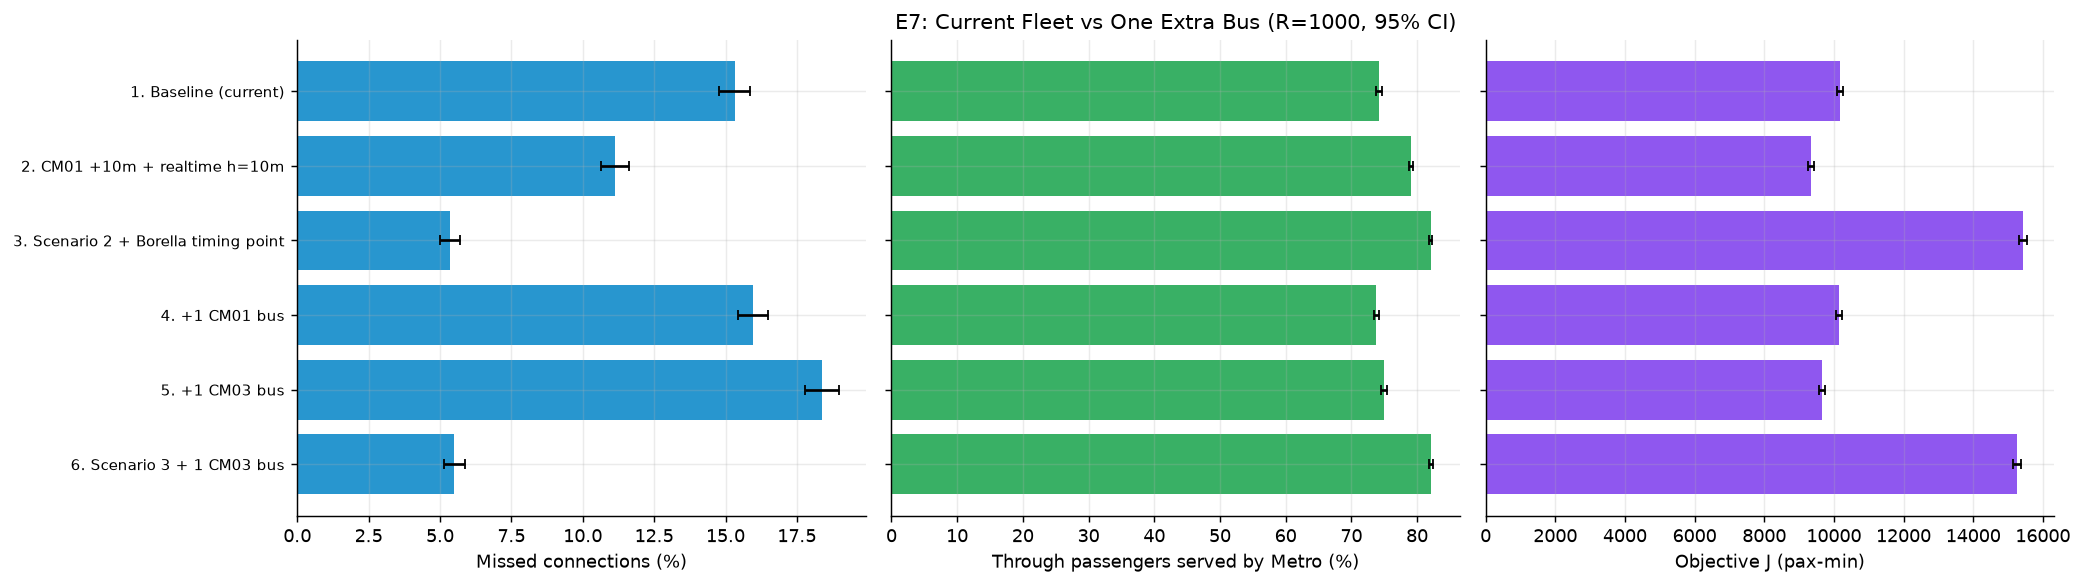


Recommended fixed timetable (2. CM01 +10m + realtime h=10m, buses {'CM01': 5, 'CM03': 6}):
Every trip leaves its terminal at the published time. Connecting buses at Borella wait up to 10 min for a late feeder (real-time ETA).
            leg     trip_id origin_dep borella terminal_arr
CM01_MAK_to_FOR CM01-MAK-01      05:40   06:59        07:30
CM01_MAK_to_FOR CM01-MAK-02      06:25   07:44        08:15
CM01_MAK_to_FOR CM01-MAK-03      06:55   08:14        08:45
CM01_MAK_to_FOR CM01-MAK-04      07:25   08:44        09:15
CM01_MAK_to_FOR CM01-MAK-05      08:25   09:44        10:15
CM01_MAK_to_FOR CM01-MAK-06      09:55   11:14        11:45
CM01_MAK_to_FOR CM01-MAK-07      10:55   12:14        12:45
CM01_MAK_to_FOR CM01-MAK-08      12:25   13:44        14:15
CM01_MAK_to_FOR CM01-MAK-09      13:40   14:59        15:30
CM01_MAK_to_FOR CM01-MAK-10      14:40   15:59        16:30
CM01_MAK_to_FOR CM01-MAK-11      15:40   16:59        17:30
CM01_MAK_to_FOR CM01-MAK-12      16:40   17:59       

In [11]:
R_FLEET = 1000  # days, shared by every scenario (CRN)
fleet_seeds = experiment_seeds("e7_fleet", R_FLEET)
opt_pol = "none" if OPT_H_MIN == 0 else "realtime"
base_scheds = shifted_schedules()
opt_scheds = shifted_schedules(**opt_shift_kw)
timing_point_kw = {**opt_shift_kw, "connector_waits_for_schedule": True}


def fleet_of(scheds, extra):
    return {route: len(bus_blocks(route_trip_list(with_extra_trips(scheds, extra), route))) for route in ROUTES}


extra_cm01 = best_extra_bus(base_scheds, "CM01")
extra_cm03 = best_extra_bus(base_scheds, "CM03")

# label, timetables (for the bus count), extra trips, day options, policy, max hold (min)
fleet_specs = [
    ("1. Baseline (current)", base_scheds, {}, {}, "none", 0.0),
    (f"2. {shift_target_route} {OPT_DELTA_MIN:+.0f}m + realtime h={OPT_H_MIN:.0f}m", opt_scheds, {}, opt_shift_kw, opt_pol, OPT_H_MIN),
    ("3. Scenario 2 + Borella timing point", opt_scheds, {}, timing_point_kw, opt_pol, OPT_H_MIN),
    ("4. +1 CM01 bus", base_scheds, extra_cm01, {}, "none", 0.0),
    ("5. +1 CM03 bus", base_scheds, extra_cm03, {}, "none", 0.0),
]

fleet_rows = []
fleet_results = {}
for label, scheds, extra, day_kw, pol, h_v in fleet_specs:
    blocks_by_route = {route: bus_blocks(route_trip_list(with_extra_trips(scheds, extra), route)) for route in ROUTES}
    days = [precompute_day_inputs(s, **day_kw, extra_trips=extra) for s in fleet_seeds]
    res = evaluate_policy_over_days(days, pol, h_v)
    late_pct = float(np.mean([late_turnaround_pct(d, blocks_by_route) for d in days]))
    fleet_results[label] = res
    fleet_rows.append({"label": label, "buses": fleet_of(scheds, extra), "res": res, "late_pct": late_pct})

# Scenario 6: the better extra bus (by J) on top of scenario 3; its trips are placed on the shifted timetable.
best_extra_route = "CM01" if fleet_results["4. +1 CM01 bus"]["J_mean"] <= fleet_results["5. +1 CM03 bus"]["J_mean"] else "CM03"
extra_best_opt = best_extra_bus(opt_scheds, best_extra_route)
label6 = f"6. Scenario 3 + 1 {best_extra_route} bus"
blocks6 = {route: bus_blocks(route_trip_list(with_extra_trips(opt_scheds, extra_best_opt), route)) for route in ROUTES}
days6 = [precompute_day_inputs(s, **timing_point_kw, extra_trips=extra_best_opt) for s in fleet_seeds]
res6 = evaluate_policy_over_days(days6, opt_pol, OPT_H_MIN)
fleet_results[label6] = res6
fleet_rows.append({"label": label6, "buses": fleet_of(opt_scheds, extra_best_opt), "res": res6,
                   "late_pct": float(np.mean([late_turnaround_pct(d, blocks6) for d in days6]))})

e7_df = pd.DataFrame([{
    "Scenario": r["label"],
    "Buses (CM01+CM03)": f"{r['buses']['CM01']}+{r['buses']['CM03']}",
    "Miss All (%)": f"{r['res']['miss_all_pct']:.2f} +/- {r['res']['miss_all_ci']:.2f}",
    "Served by Metro (%)": f"{r['res']['served_pct']:.2f} +/- {r['res']['served_ci']:.2f}",
    "Mean Wait (min)": f"{r['res']['mean_wait_min']:.2f} +/- {r['res']['mean_wait_ci']:.2f}",
    "Hold Cost": round(r["res"]["hold_cost"], 1),
    "J (pax-min)": f"{r['res']['J_mean']:.1f} +/- {r['res']['J_ci']:.1f}",
    "Late turnarounds (%)": round(r["late_pct"], 1),
} for r in fleet_rows])
print(f"=== E7: Current fleet vs one extra bus (R = {R_FLEET} CRN days, 95% CI) ===")
print(e7_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.6))
y_pos = np.arange(len(fleet_rows))
labels = [r["label"] for r in fleet_rows]
for ax, key, ci_key, color, xlabel in (
    (axes[0], "miss_all_pct", "miss_all_ci", "#0284c7", "Missed connections (%)"),
    (axes[1], "served_pct", "served_ci", "#16a34a", "Through passengers served by Metro (%)"),
    (axes[2], "J_mean", "J_ci", "#7c3aed", "Objective J (pax-min)"),
):
    ax.barh(y_pos, [r["res"][key] for r in fleet_rows], xerr=[r["res"][ci_key] for r in fleet_rows], color=color, alpha=0.85, capsize=3)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels if ax is axes[0] else [], fontsize=8.5)
    ax.invert_yaxis()
    ax.set_xlabel(xlabel)
axes[1].set_title(f"E7: Current Fleet vs One Extra Bus (R={R_FLEET}, 95% CI)")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "fleet_comparison.png", bbox_inches="tight")
plt.show()

# Recommended fixed timetable: the lowest-J scenario that runs on the current fleet.
current_fleet_rows = [r for r in fleet_rows if r["buses"] == BASE_FLEET]
recommended = min(current_fleet_rows, key=lambda r: r["res"]["J_mean"])
rec_scheds = opt_scheds if recommended["label"] != fleet_rows[0]["label"] else base_scheds
rec_table = pd.concat([
    df.assign(
        origin_dep=df["origin_sched_min"].map(format_minutes_to_hhmm),
        borella=df["borella_sched_min"].map(format_minutes_to_hhmm),
        terminal_arr=df["dest_sched_min"].map(format_minutes_to_hhmm),
    )[["leg", "trip_id", "origin_dep", "borella", "terminal_arr"]]
    for df in rec_scheds.values()
], ignore_index=True)
DATA_OUT_DIR = FIGURES_DIR.parent / "data"
DATA_OUT_DIR.mkdir(parents=True, exist_ok=True)
rec_table.to_csv(DATA_OUT_DIR / "recommended_timetable.csv", index=False)
print(f"\nRecommended fixed timetable ({recommended['label']}, buses {recommended['buses']}):")
print(f"Every trip leaves its terminal at the published time. Connecting buses at Borella wait up to {OPT_H_MIN:.0f} min "
      f"for a late feeder (real-time ETA)" + (" and never leave Borella before their published time." if "timing point" in recommended["label"] else "."))
print(rec_table.to_string(index=False))


=== Extension X5: Sensitivity around the joint optimal policy (base miss = 11.91 +/- 0.99%, base J per passenger = 82.2 +/- 1.3 pax-min, R = 250, 95% CI) ===
                           Parameter  Low Miss (%)  Low Miss CI  High Miss (%)  High Miss CI  Miss Swing (pp)  Low J/pax  Low J/pax CI  High J/pax  High J/pax CI
 Stop arrival scale (0.75x vs 1.25x)          8.17         0.86          20.90          1.26            12.73      76.88          1.12       92.35           1.61
        Walk time w (2.0 vs 6.5 min)         10.95         0.94          13.87          1.04             2.92      80.56          1.28       85.59           1.33
      Transfer mean (3.0 vs 8.0 pax)         10.62         1.08          13.32          1.04             2.71      82.12          1.27       83.17           1.32
      Peak car speed (18 vs 30 km/h)          9.67         0.94          11.69          0.95             2.02      85.42          1.38       78.13           1.11
Passenger patience P (30 vs 120 

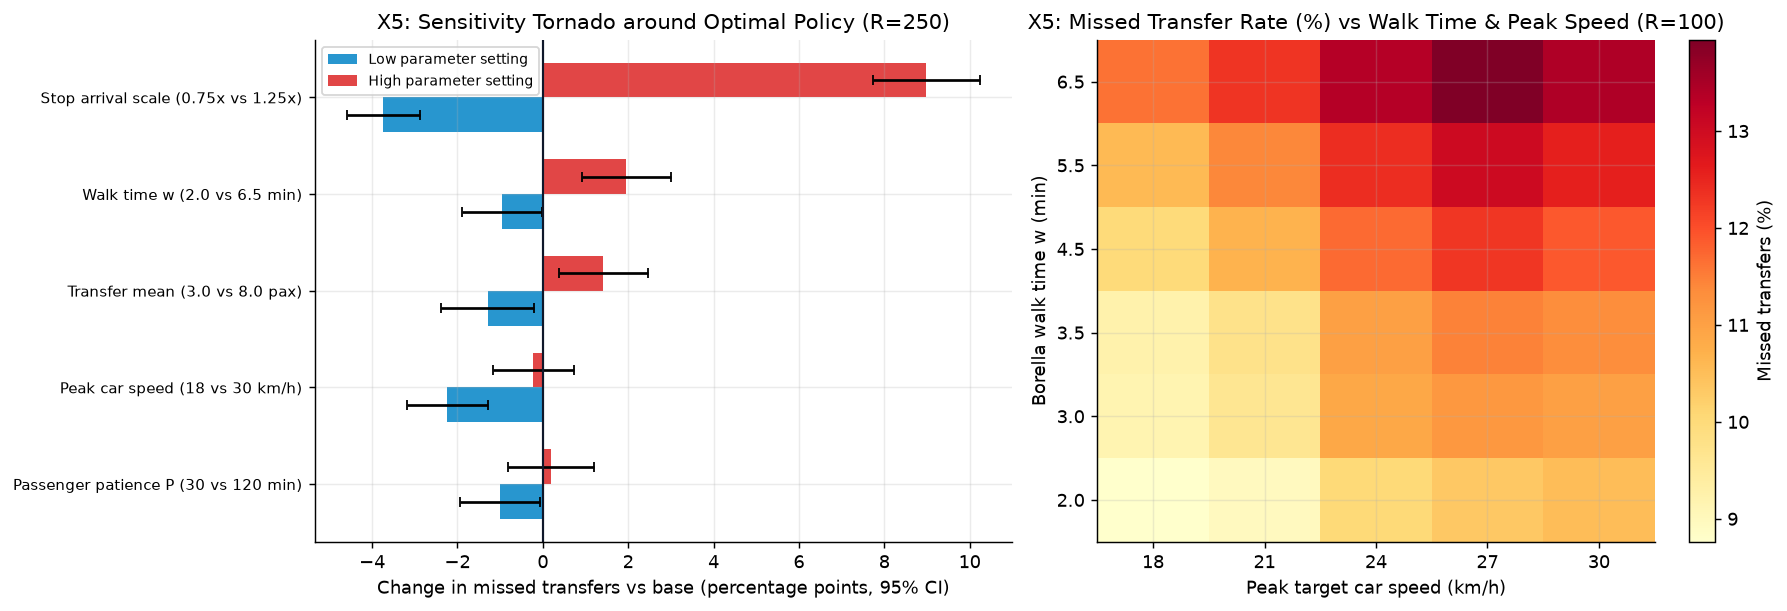


=== Extension X6: Vectorized Markov Chain Benchmark (2000 days x 240 slots) ===
Python loop time: 0.1228 s | Vectorized NumPy time: 0.0099 s | Measured speed-up: 12.4x


In [12]:
R_SENS = 250  # days, shared by every one-at-a-time case (CRN)
sens_seeds = experiment_seeds("sensitivity", R_SENS)
opt_shift_kw = {"shift_cm03_min": OPT_DELTA_MIN} if shift_target_route == "CM03" else {"shift_cm01_min": OPT_DELTA_MIN}
opt_pol = "none" if OPT_H_MIN == 0 else "realtime"

sens_base_days = [precompute_day_inputs(s, **opt_shift_kw) for s in sens_seeds]
sens_base = evaluate_policy_over_days(sens_base_days, opt_pol, OPT_H_MIN)

v_reach_min = expected_speed_for_jam_param(JAM_PARAM_MAX)
v_reach_max = expected_speed_for_jam_param(JAM_PARAM_MIN)
v_pk_low = float(round(max(v_reach_min + 1.0, target_peak_kmph - 6.0), 1))
v_pk_high = float(round(min(v_reach_max - 1.0, target_peak_kmph + 6.0), 1))

sensitivity_specs = [
    ("Walk time w (2.0 vs 6.5 min)", {"walk_time_min": 2.0}, {"walk_time_min": 6.5}),
    ("Passenger patience P (30 vs 120 min)", {"patience_min": 30.0}, {"patience_min": 120.0}),
    ("Transfer mean (3.0 vs 8.0 pax)", {"transfer_mean_pax": 3.0}, {"transfer_mean_pax": 8.0}),
    ("Stop arrival scale (0.75x vs 1.25x)", {"arrival_rate_scale": 0.75}, {"arrival_rate_scale": 1.25}),
    (f"Peak car speed ({v_pk_low:.0f} vs {v_pk_high:.0f} km/h)", {"peak_speed_kmph": v_pk_low}, {"peak_speed_kmph": v_pk_high}),
]


def run_sens_case(case_kwargs, seeds=sens_seeds):
    p_pk_mat = P_peak
    if "peak_speed_kmph" in case_kwargs:
        p_pk_val = calibrate_jam_param_bisection(case_kwargs["peak_speed_kmph"])
        p_pk_mat = build_parametric_transition_matrix(p_pk_val)
    days = [
        precompute_day_inputs(
            s,
            **opt_shift_kw,
            walk_time_min=case_kwargs.get("walk_time_min", WALK_TIME_PLACEHOLDER_MIN),
            transfer_mean_pax=case_kwargs.get("transfer_mean_pax", TRANSFER_MEAN_PAX),
            arrival_rate_scale=case_kwargs.get("arrival_rate_scale", 1.0),
            p_peak_mat=p_pk_mat,
            patience_min=case_kwargs.get("patience_min", PASSENGER_PATIENCE_MIN),
        )
        for s in seeds
    ]
    return evaluate_policy_over_days(
        days,
        opt_pol,
        OPT_H_MIN,
        walk_time_min=case_kwargs.get("walk_time_min", WALK_TIME_PLACEHOLDER_MIN),
    )


tornado_rows = []
for label, low_kw, high_kw in sensitivity_specs:
    low_res = run_sens_case(low_kw)
    high_res = run_sens_case(high_kw)
    tornado_rows.append({
        "Parameter": label,
        "Low Miss (%)": low_res["miss_all_pct"],
        "Low Miss CI": low_res["miss_all_ci"],
        "High Miss (%)": high_res["miss_all_pct"],
        "High Miss CI": high_res["miss_all_ci"],
        "Miss Swing (pp)": abs(high_res["miss_all_pct"] - low_res["miss_all_pct"]),
        "Low J/pax": low_res["J_per_pax"],
        "Low J/pax CI": low_res["J_per_pax_ci"],
        "High J/pax": high_res["J_per_pax"],
        "High J/pax CI": high_res["J_per_pax_ci"],
    })

tornado_df = pd.DataFrame(tornado_rows).sort_values("Miss Swing (pp)", ascending=True)
base_miss_sens = sens_base["miss_all_pct"]
print(f"=== Extension X5: Sensitivity around the joint optimal policy (base miss = {base_miss_sens:.2f} +/- {sens_base['miss_all_ci']:.2f}%, "
      f"base J per passenger = {sens_base['J_per_pax']:.1f} +/- {sens_base['J_per_pax_ci']:.1f} pax-min, R = {R_SENS}, 95% CI) ===")
print(tornado_df.sort_values("Miss Swing (pp)", ascending=False).round(2).to_string(index=False))

R_SENS_2D = 100  # days per grid cell
sens_2d_seeds = sens_seeds[:R_SENS_2D]
walk_sweep = np.array([2.0, 3.0, 3.5, 4.5, 5.5, 6.5])
speed_sweep = np.round(np.linspace(v_pk_low, v_pk_high, 5), 1)
sens_2d = np.zeros((len(walk_sweep), len(speed_sweep)))
for r_i, w_val in enumerate(walk_sweep):
    for c_i, v_pk in enumerate(speed_sweep):
        out_2d = run_sens_case({"walk_time_min": float(w_val), "peak_speed_kmph": float(v_pk)}, seeds=sens_2d_seeds)
        sens_2d[r_i, c_i] = out_2d["miss_all_pct"]

fig, axes = plt.subplots(1, 2, figsize=(14.0, 4.8))
y_idx = np.arange(len(tornado_df))
axes[0].barh(y_idx - 0.18, tornado_df["Low Miss (%)"] - base_miss_sens, height=0.36, xerr=tornado_df["Low Miss CI"],
             color="#0284c7", alpha=0.85, capsize=3, label="Low parameter setting")
axes[0].barh(y_idx + 0.18, tornado_df["High Miss (%)"] - base_miss_sens, height=0.36, xerr=tornado_df["High Miss CI"],
             color="#dc2626", alpha=0.85, capsize=3, label="High parameter setting")
axes[0].axvline(0.0, color="#0f172a", linewidth=1.2)
axes[0].set_yticks(y_idx)
axes[0].set_yticklabels(tornado_df["Parameter"], fontsize=8.5)
axes[0].set_xlabel("Change in missed transfers vs base (percentage points, 95% CI)")
axes[0].set_title(f"X5: Sensitivity Tornado around Optimal Policy (R={R_SENS})")
axes[0].legend(fontsize=8)

im_s = axes[1].imshow(sens_2d, aspect="auto", origin="lower", cmap="YlOrRd")
axes[1].set_xticks(range(len(speed_sweep)))
axes[1].set_xticklabels([f"{v:.0f}" for v in speed_sweep])
axes[1].set_yticks(range(len(walk_sweep)))
axes[1].set_yticklabels([f"{w:.1f}" for w in walk_sweep])
axes[1].set_xlabel("Peak target car speed (km/h)")
axes[1].set_ylabel("Borella walk time w (min)")
axes[1].set_title(f"X5: Missed Transfer Rate (%) vs Walk Time & Peak Speed (R={R_SENS_2D})")
plt.colorbar(im_s, ax=axes[1], label="Missed transfers (%)")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "sensitivity_tornado.png", bbox_inches="tight")
plt.show()

N_CHAINS_BENCH = 2000
N_SLOTS_BENCH = 240
bench_seeds = experiment_seeds("benchmark", 2)
bench_rng_loop = np.random.default_rng(bench_seeds[0])
bench_rng_vec = np.random.default_rng(bench_seeds[1])

t0 = time.perf_counter()
loop_out = np.vstack([simulate_markov_chain_loop(P_peak, N_SLOTS_BENCH, bench_rng_loop) for _ in range(N_CHAINS_BENCH)])
t_loop_sec = time.perf_counter() - t0

t1 = time.perf_counter()
vec_out = simulate_markov_chain_vectorized(P_peak, N_SLOTS_BENCH, N_CHAINS_BENCH, bench_rng_vec)
t_vec_sec = time.perf_counter() - t1

assert loop_out.shape == vec_out.shape == (N_CHAINS_BENCH, N_SLOTS_BENCH)
speedup = t_loop_sec / max(1e-9, t_vec_sec)
print(f"\n=== Extension X6: Vectorized Markov Chain Benchmark ({N_CHAINS_BENCH} days x {N_SLOTS_BENCH} slots) ===")
print(f"Python loop time: {t_loop_sec:.4f} s | Vectorized NumPy time: {t_vec_sec:.4f} s | Measured speed-up: {speedup:.1f}x")

## 6. Discussion and limitations

*Provenance: AI-generated, then revised after review.*

### Key Insights

1. **Diagnosis of the current timetable (`E1`):** With Borella placed by road distance, every scheduled connection is feasible on paper. The tightest are the afternoon Kadawatha-to-Pettah pairs `CM03-KAD-05..08` (6.6 min slack) and the morning Pettah-to-Kadawatha `CM01-FOR-03` (8.4 min). Traffic variability still breaks about one in seven connections (`15.4%` missed, `10.3%` of through passengers lost to other transport), mostly through timing (`12.9%`) rather than full buses (`2.5%`). Group A (Kadawatha to Pettah, `21.8%`) misses twice as often as Group B (`10.8%`). Three evening Group A feeders (`CM03-KAD-09..11`) have no CM01 connection at all, which no holding rule can fix.
2. **Holding alone vs a coordinated shift (`E2` & `E3`):** Real-time holding of up to 3 min cuts misses to about `12.6%`. Shifting CM01 by $+10$ min on its own helps Group A but hurts Group B (`20.6%`), so the shift only pays off combined with holding. The joint policy (CM01 $+10$ min, real-time holding up to $h = 10$ min) gives `11.0%` missed and `4.2%` lost, with the lowest cost $J$. Shifting CM03 by $-10$ min scores within the confidence interval of this ($J$ = 9323 vs 9307 pax-min, CI about $\pm 215$), so the choice between the two routes is not decisive.
3. **The hold limit is an operating choice, not an optimum:** $J$ still falls at $h = 10$ min, the longest hold tested. The objective only charges holding to passengers already on board, not knock-on delay to the bus's later trips or to people waiting downstream, so it undervalues the cost of long holds. We treat 10 min as the longest hold an operator would accept.
4. **Value of real-time ETA holding (`E4`):** At the joint policy, schedule holding and real-time holding miss about the same share of transfers (`10.7%` vs `10.7-11.8%`), but real-time holding spends about a third of the on-board hold minutes (`~210` vs `609` pax-min) because it skips holds for feeders that cannot make it. Its advantage shrinks as the ETA error grows to 4 min.
5. **Fleet capacity vs coordination (`E5`):** Removing the 80-passenger limit lowers Group B misses from `12.1%` to `6.5%` but barely changes Group A, so capacity matters for the Pettah-to-Kadawatha direction only.
6. **Ticket validity (`E6`):** With patience and validity limits removed, `99.0%` (baseline) and `99.1%` (joint policy) of through passengers who board do so within 120 min of reaching Borella, so a 2-hour validity would rarely bind. About `2.2%` (baseline) find no later bus that day.
7. **The current fleet is enough (`E7`, Check 12):** The published timetables need at least 5 CM01 and 6 CM03 buses with 10-min turnarounds, and any whole-route shift keeps that number. The recommended policy (CM01 $+10$ min, real-time holding up to 10 min) therefore needs no extra buses, keeps fixed published terminal departures, and is saved as `data/recommended_timetable.csv`.
8. **One extra bus does not fix missed connections (`E7`):** An extra CM01 bus placed to even out headways adds trips at Borella 10:19 and 14:19, when no Kadawatha feeder arrives, so it serves no extra transfers. It also takes local passengers from the next regular bus, which then runs lighter, reaches Borella earlier and leaves before transferring passengers arrive (`16.0%` vs `15.3%` missed). An extra CM03 bus serves slightly more through passengers by Metro (`75.0%` vs `74.2%`) and lowers $J$ by about 5%, far less than the 8% from coordination alone. Adding a bus to the joint policy changes almost nothing (scenario 6 vs 3). Coordination, not fleet size, is what makes through-ticketing work.
9. **A Borella timing point halves misses but delays riders already on board:** If connectors never leave Borella before their published time, misses fall from `15.1%` to `6.7%` for the baseline (operating check, R = 300) and from `11.1%` to `5.4%` for the joint policy (`E7`, R = 1000). But every connector that reaches Borella early now waits there with its on-board passengers, which adds about 5,600 pax-min of on-board delay per day and raises $J$ from 9340 to 15431 pax-min. It is the most predictable option for transferring passengers but not the best overall under the 2:1 weighting. Whether Metro buses already wait at Borella when early is the most valuable next field check.
10. **Fixed timetables have little turnaround margin:** In about `19%` of planned 10-min turnarounds, the simulated bus reaches the terminal too late to start its next trip on time, in every scenario. The published timetable is tight even before holding is added.

### Key Limitations and Future Work

- **Synthetic passenger demand and walk time:** Stop-level arrival rates $\lambda_{s,0}$, transfer demand $m_f$ and the Borella walk $w = 3.5$ min are placeholders. The sensitivity analysis shows stop demand drives the miss rate most (`8.2%` to `20.9%` for $0.75\times$ to $1.25\times$), then walk time.
- **Borella position from road distance:** Borella's scheduled time assumes constant speed between the bracketing timepoints. With the midpoint ($\lambda = 0.5$) instead, the afternoon Group A and morning Group B pairs would be scheduled $0.5$ min short of the walk, so the baseline depends on where Borella actually sits. GPS records from LMT-GO buses would replace this assumption.
- **Stop coordinates are geocoded:** Road distances come from OSRM routing between geocoded stops. Apeksha Hospital and Kelaniya University were moved onto the bus road; their real halt positions are unverified.
- **Independent corridor Markov chains:** Each direction has one traffic state for its whole length and evolves independently. Real congestion at shared junctions would correlate feeder and connector delays.
- **Pooled traffic targets:** The Markov chain is calibrated to the mean speed of six `cmb_traffic` corridors. Per-leg speed factors $\alpha_\ell$ correct the level but not differences in variability, and the transition matrix shape is assumed rather than fitted to the observed state shares.
- **Bus duties are checked, not simulated:** The fleet analysis links trips into bus duties, but the simulation still runs each trip from its published time, so a late or held bus does not delay its next trip. With about 19% of turnarounds already late, holding looks cheaper than it is.
- **Fleet size is a lower bound:** 5 + 6 buses is the minimum the timetables need with 10-min turnarounds and no route swapping. Spare buses, depot location and driver rules are unknown.
- **Extra bus placement:** The extra bus is placed by a headway rule within the route's current service hours, not to target transfers. An evening CM01 trip aimed at the three unconnected Kadawatha feeders was not tested.
- **Timing point settings:** The timing-point scenario reuses the shift and hold chosen without it; they were not re-optimised.
- **Passenger behaviour assumptions:** Patience $P = 60$ min, validity $V = 120$ min and the 60 min alternative-travel penalty are assumptions. Passengers judge the next bus by its timetable time, not a live prediction.
- **Borella boarding simplifications:** Boarding at Borella does not add to the connector's dwell, and through passengers are not counted in the feeder's load.


## 7. References

*Provenance: AI-generated.*

1. A. M. Law, *Simulation Modeling and Analysis*, 5th ed. New York, NY, USA: McGraw-Hill, 2015.
2. T. Amalan, "Analysis of Bus Passenger Demand and Supply: Case Study on Western Province, Sri Lanka," *International Journal of Scientific Research and Management (IJSRM)*, vol. 9, no. 11, pp. 2544-2554, Nov. 2021, doi: 10.18535/ijsrm/v9i11.em03.
3. N. I. Senaratna, "Colombo Traffic Index (`cmb_traffic`): Open Urban Road Travel-Time Dataset," GitHub repository (MIT License). [Online]. Available: https://github.com/nuuuwan/cmb_traffic
4. Lanka Metro Transit, "LMT-GO Official Route Schedules and Bus Specifications (Routes CM01 and CM03)," LMT-GO mobile application, accessed Nov. 10, 2026; cross-checked with https://metrobus.lk.
5. R. W. Hall, M. Dessouky, and Q. Lu, "Optimal holding times at transfer stations," *Computers & Industrial Engineering*, vol. 40, no. 4, pp. 379-397, 2001, doi: 10.1016/S0360-8352(01)00039-0.
6. S. M. Ross, *Simulation*, 6th ed. London, U.K.: Academic Press, 2023.